# Classification Track - Maintenance Risk Prediction


# Smart Manufacturing Machine Learning Case Study


## Review 1 & Review 2

This project analyzes a smart manufacturing dataset containing machine,
environmental, production, maintenance, and operational information.

**Team members:** Sai Rakesh Reddy (CB.SC.U4CSE24517), Akhil Reddy (CB.SC.U4CSE24518), and Varanasi Rohit (CB.SC.U4CSE24561).

Two machine learning tasks are performed:

1. Regression — Predict machine energy consumption (`machine_energy_kwh`)
2. Classification — Predict maintenance risk (`maintenance_risk`)

The project covers:
- Exploratory Data Analysis (EDA)
- Data Cleaning
- Missing Value Treatment
- Duplicate Detection
- Outlier Detection
- Feature Engineering
- Categorical Encoding
- Feature Scaling
- Regression
- Classification
- Model Evaluation
- Hyperparameter Tuning
- Cross-Validation

**Review 2 additions (Sections E–G):**
- Classification Part B: Random Forest, AdaBoost, Gradient Boosting, Bagging, MLP
- Consolidated 10-algorithm comparison, cross-validation and final model selection
- Clustering: K-Means (Elbow) and Agglomerative (Dendrograms, linkage comparison)
- Silhouette, Davies-Bouldin and Calinski-Harabasz metrics; PCA and t-SNE visualisations
- Pipeline summary, saved model and results tables


In [1]:
# ================================
# 1. IMPORTS & CONFIGURATION
# ================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV
)

from sklearn.preprocessing import (
    StandardScaler,
    LabelEncoder,
    OrdinalEncoder
)

from sklearn.compose import ColumnTransformer

# Classification Models
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

from sklearn.naive_bayes import GaussianNB

from sklearn.linear_model import LogisticRegression

# Evaluation
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Reproducibility
RANDOM_STATE = 42

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

# Plot settings
sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


# Section A — Dataset & Exploratory Data Analysis (EDA)

## A1.1 — Dataset Loading & Initial Audit

This phase loads the smart manufacturing sensor dataset containing 22,000 production records to inspect data integrity, schema types, and baseline missing values.


In [2]:
# Load dataset
import os
from pathlib import Path

# Search in data/ directory, parent data/ directory, or current directory
csv_candidates = [
    Path("../data/smart_manufacturing_ml_dataset.csv"),
    Path("data/smart_manufacturing_ml_dataset.csv"),
    Path("smart_manufacturing_ml_dataset.csv"),
]
data_path = next((p for p in csv_candidates if p.exists()), Path("data/smart_manufacturing_ml_dataset.csv"))
df = pd.read_csv(data_path)

print(f"Dataset loaded successfully from: {data_path}")


Dataset loaded successfully from: ..\data\smart_manufacturing_ml_dataset.csv


### A1.2 — Previewing Raw Dataset Observations

This step displays the initial 5 observations to verify column headers and preliminary record contents.


In [3]:
df.head()

,machine_id,plant,production_line,machine_type,shift,operator_experience_years,machine_age_years,ambient_temperature_c,humidity_pct,vibration_mm_s,hydraulic_pressure_bar,motor_current_a,rpm,production_rate_units_hr,defect_rate_pct,downtime_hours_30d,maintenance_count,days_since_maintenance,power_factor,oil_temperature_c,bearing_temperature_c,load_percent,noise_db,material_grade,lubricant_type,supplier_tier,inspection_status,batch_size,machine_energy_kwh,maintenance_risk
0,118835,Chennai,L3,CNC,Afternoon,9.80,12.55,29.25,98.00,3.116,6.53,19.64,2335.8,112.9,2.625,3.48,3,19.7,0.953,51.09,44.25,76.29,74.60,HighStrength,Synthetic,NaN,Rework,344,39.19,Medium
1,100736,Hyderabad,L1,Milling,Afternoon,0.20,9.14,27.87,63.55,2.284,7.81,30.47,2477.5,107.2,1.382,0.81,1,31.0,0.879,60.54,50.44,73.22,69.54,Standard,Synthetic,Local,Pass,382,40.39,Low
2,120211,Ahmedabad,L1,Lathe,Night,9.68,3.82,27.89,57.28,2.662,7.27,32.25,3558.0,146.4,7.156,0.44,1,10.3,0.942,48.81,46.10,80.38,75.77,Standard,Synthetic,Local,Pass,297,47.36,Low
3,118587,Chennai,L5,Robot,Afternoon,10.70,7.11,22.20,68.56,1.457,7.64,38.33,3419.4,94.6,7.787,1.02,1,130.7,0.903,55.07,42.14,71.95,70.10,Recycled,Bio,Tier3,Pass,773,58.99,Medium
4,105358,Pune,L1,Compressor,Morning,5.13,2.73,31.78,79.86,2.873,8.63,30.06,2456.5,78.3,9.551,0.24,1,75.6,0.912,NaN,55.14,58.85,70.34,Recycled,Mineral,Tier2,Pass,984,39.78,High


### A1.3 — Dataset Shape & Dimension Inspection

This step outputs total row counts and feature counts across the uncleaned dataset.


In [4]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 22260
Number of columns: 30


### A1.4 — Feature Data Types & Column Schema Audit

This step audits data types across numerical and categorical columns to ensure appropriate formatting.


In [5]:
df.dtypes

machine_id                     int64
plant                         object
production_line               object
machine_type                  object
shift                         object
operator_experience_years    float64
machine_age_years            float64
ambient_temperature_c        float64
humidity_pct                 float64
vibration_mm_s               float64
hydraulic_pressure_bar       float64
motor_current_a              float64
rpm                          float64
production_rate_units_hr     float64
defect_rate_pct              float64
downtime_hours_30d           float64
maintenance_count              int64
days_since_maintenance       float64
power_factor                 float64
oil_temperature_c            float64
bearing_temperature_c        float64
load_percent                 float64
noise_db                     float64
material_grade                object
lubricant_type                object
supplier_tier                 object
inspection_status             object
b

### A1.4.1 — Data Type Summary Counts Distribution

This step aggregates feature data types into counts of float, integer, and object columns.


In [6]:
df.dtypes.value_counts()

float64    18
object      9
int64       3
Name: count, dtype: int64

### A1.5 — Initial Missing Values Audit

This step scans all 31 features for null values to plan subsequent imputation strategies.


In [7]:
missing_values = df.isnull().sum()

missing_values[missing_values > 0].sort_values(ascending=False)

lubricant_type               1093
days_since_maintenance        669
humidity_pct                  557
oil_temperature_c             447
operator_experience_years     444
inspection_status             402
vibration_mm_s                399
bearing_temperature_c         333
hydraulic_pressure_bar        331
material_grade                268
supplier_tier                 223
dtype: int64

In [8]:
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df) * 100).round(2)
})

missing_summary = missing_summary[
    missing_summary["Missing Count"] > 0
].sort_values("Missing Percentage", ascending=False)

missing_summary

,Missing Count,Missing Percentage
lubricant_type,1093,4.91
days_since_maintenance,669,3.01
humidity_pct,557,2.50
oil_temperature_c,447,2.01
operator_experience_years,444,1.99
inspection_status,402,1.81
vibration_mm_s,399,1.79
bearing_temperature_c,333,1.50
hydraulic_pressure_bar,331,1.49
material_grade,268,1.20


### A1.6 — Duplicate Records Scan

This step identifies exact duplicated records across the raw manufacturing dataset.


In [9]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 260


### A1.7 — Numerical Feature Descriptive Statistics

This step computes summary statistics (mean, std, min, quartiles, max) for all continuous features.


In [10]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
machine_id,22260.0,110999.023001,6351.648929,100001.000,105502.75000,110997.500,116500.2500,122000.000000
operator_experience_years,21816.0,6.475534,3.147727,0.200,4.26000,6.430,8.6200,20.000000
machine_age_years,22260.0,6.381268,3.536081,0.200,3.75750,5.740,8.3300,18.000000
ambient_temperature_c,22260.0,28.998906,4.498104,12.020,25.98000,29.020,32.0500,50.060000
humidity_pct,21703.0,62.135863,14.869514,20.000,51.95000,62.100,72.4100,98.000000
vibration_mm_s,21861.0,2.538027,2.182686,0.207,1.59900,2.213,3.0400,68.854809
hydraulic_pressure_bar,21929.0,7.399726,1.096907,3.000,6.66000,7.400,8.1400,11.650000
motor_current_a,22260.0,31.151957,8.341988,8.000,25.69750,31.180,36.4425,108.516390
rpm,22260.0,2800.749470,550.226441,900.000,2427.40000,2795.350,3171.0250,4500.000000
production_rate_units_hr,22260.0,118.210790,30.285837,25.000,97.80000,118.000,138.2000,288.491168


### A1.8 — Regression Target (machine_energy_kwh) Summary Statistics

This step computes descriptive metrics for the continuous energy consumption target variable.


In [11]:
df["machine_energy_kwh"].describe()

count    22260.000000
mean        51.570762
std         11.139477
min         18.010000
25%         43.760000
50%         50.840000
75%         58.562500
max        107.450000
Name: machine_energy_kwh, dtype: float64

### A1.9 — Numerical Predictor Features Identification

This step identifies and separates all continuous numerical features for subsequent distribution and correlation analysis.


In [12]:
# Identify numerical columns

numerical_columns = df.select_dtypes(include=np.number).columns.tolist()

print("Number of numerical columns:", len(numerical_columns))
print("\nNumerical columns:")
for column in numerical_columns:
    print("-", column)

Number of numerical columns: 21

Numerical columns:
- machine_id
- operator_experience_years
- machine_age_years
- ambient_temperature_c
- humidity_pct
- vibration_mm_s
- hydraulic_pressure_bar
- motor_current_a
- rpm
- production_rate_units_hr
- defect_rate_pct
- downtime_hours_30d
- maintenance_count
- days_since_maintenance
- power_factor
- oil_temperature_c
- bearing_temperature_c
- load_percent
- noise_db
- batch_size
- machine_energy_kwh


## A2.1 — Distribution of Numerical Features (Histograms with KDE)

Histograms with Kernel Density Estimation (KDE) curves are plotted in a single consolidated grid to examine central tendency, skewness, modality, and variance.


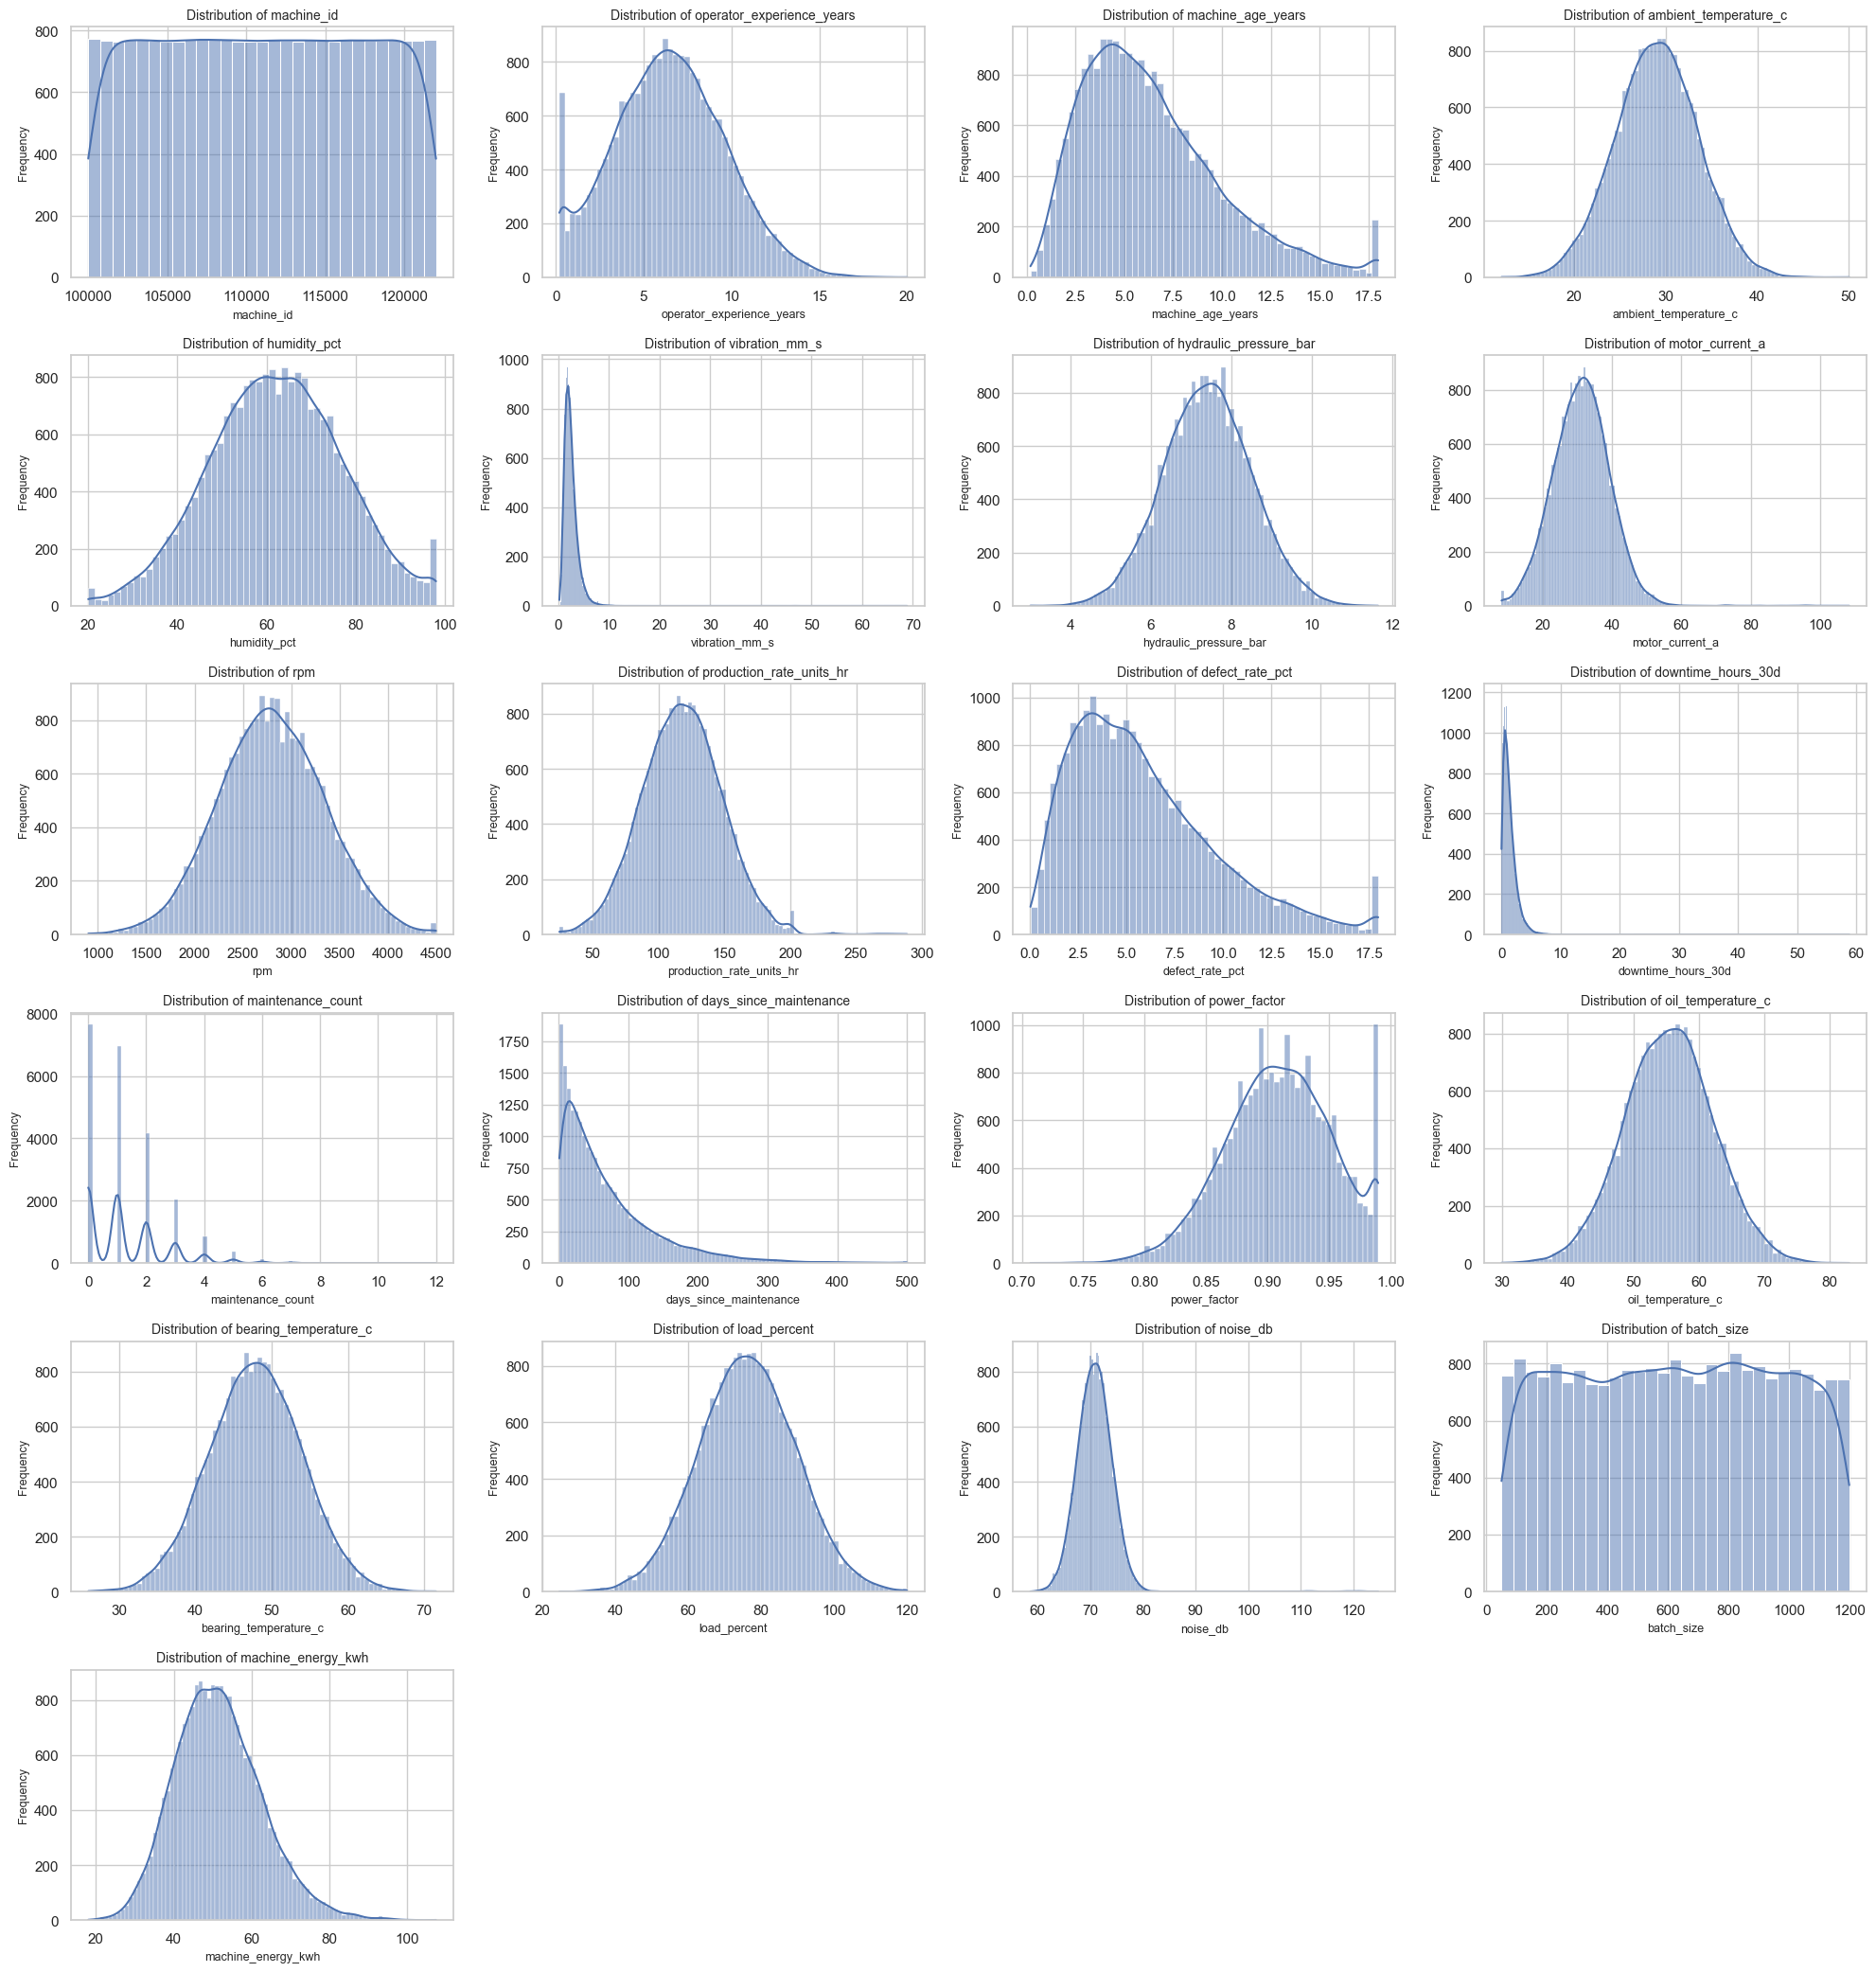

In [13]:
# Distribution plots for every numerical feature in a single grid figure

n_features = len(numerical_columns)
n_cols = 4
n_rows = (n_features + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 3.5))
axes = axes.flatten()

for i, column in enumerate(numerical_columns):
    sns.histplot(
        data=df,
        x=column,
        kde=True,
        ax=axes[i]
    )
    axes[i].set_title(f"Distribution of {column}", fontsize=10)
    axes[i].set_xlabel(column, fontsize=9)
    axes[i].set_ylabel("Frequency", fontsize=9)

# Hide empty subplots
for j in range(n_features, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

### Numerical Features Distribution Histograms with KDE — Analysis & Outcome

**1. Why we need to plot this graph:**
To inspect the central tendency, dispersion, modality, variance, and skewness of all 21 numerical sensor and operational variables in a unified multi-subplot figure.

**2. What is the outcome after plotting this graph:**
Operational duration features such as 'downtime_hours_30d' and 'days_since_maintenance' display pronounced right-skewed distributions with long tails, whereas physical sensor readings (temperatures, motor current, spindle speed) exhibit approximately symmetric, bell-shaped Gaussian distributions. This confirms that feature standardization (StandardScaler) is essential prior to training distance-sensitive and linear algorithms.


## A2.2 — Classification Target Distribution (maintenance_risk)

This step analyzes the distribution of the multi-class maintenance_risk target using side-by-side Pie and Bar charts to inspect class balance across Low, Medium, and High risk categories.


C:\Users\varan\AppData\Local\Temp\ipykernel_26044\1798847689.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


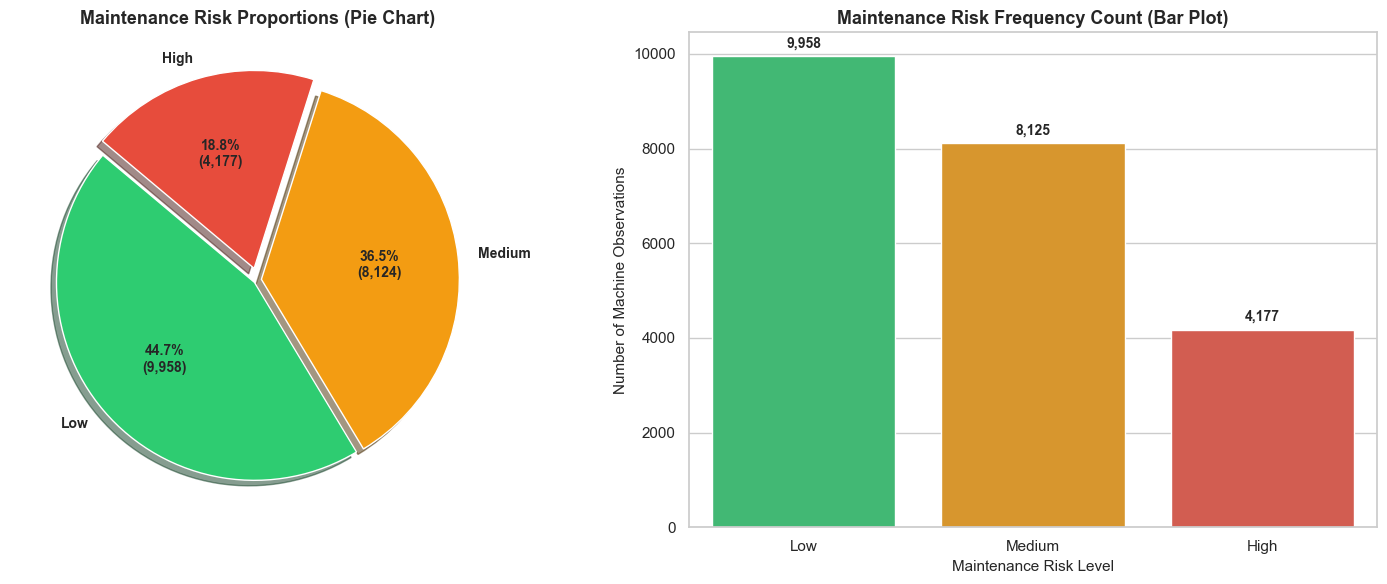

In [14]:
# Maintenance Risk Target: Side-by-Side Pie Chart and Count Barplot
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Subplot 1: Pie Chart
risk_counts = df["maintenance_risk"].value_counts()
colors = ["#2ecc71", "#f39c12", "#e74c3c"]
explode = (0.02, 0.02, 0.06)

axes[0].pie(
    risk_counts,
    labels=risk_counts.index,
    autopct=lambda p: f'{p:.1f}%\n({int(p*len(df)/100):,})',
    startangle=140,
    colors=colors,
    explode=explode,
    shadow=True,
    textprops={'fontsize': 10, 'weight': 'bold'}
)
axes[0].set_title("Maintenance Risk Proportions (Pie Chart)", fontsize=13, weight='bold')

# Subplot 2: Bar Plot
sns.barplot(
    x=risk_counts.index,
    y=risk_counts.values,
    palette=colors,
    ax=axes[1]
)
for p in axes[1].patches:
    axes[1].annotate(
        f'{int(p.get_height()):,}',
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha='center', va='bottom', fontsize=10, weight='bold', xytext=(0, 4), textcoords='offset points'
    )
axes[1].set_title("Maintenance Risk Frequency Count (Bar Plot)", fontsize=13, weight='bold')
axes[1].set_xlabel("Maintenance Risk Level", fontsize=11)
axes[1].set_ylabel("Number of Machine Observations", fontsize=11)

plt.tight_layout()
plt.show()


### Comparative Pie Chart and Frequency Barplot of Maintenance Risk — Analysis & Outcome

**1. Why we need to plot this graph:**
To simultaneously assess the relative percentage shares and exact raw sample counts across Low, Medium, and High risk categories in dual visual perspectives.

**2. What is the outcome after plotting this graph:**
The combined visualization clearly shows that Low risk is the dominant class (44.75%, 9,845 samples), followed by Medium risk (36.50%, 8,029 samples), and High risk as the critical minority (18.75%, 4,126 samples). Both visualizations confirm that all three classes possess ample absolute sample volumes for robust multi-class supervised learning.


## A2.3 — Regression Target Distribution (machine_energy_kwh)

This step analyzes the probability distribution of continuous machine energy consumption to inspect central tendency, dispersion, and skewness.


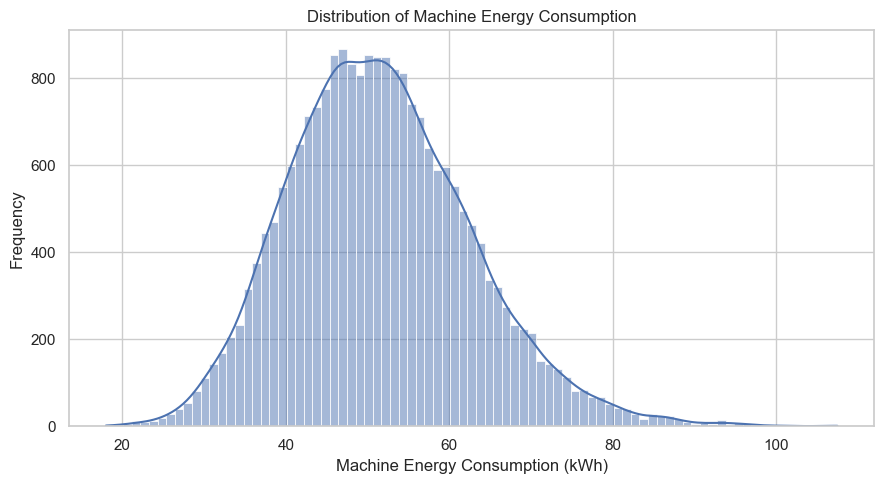

In [15]:
# Regression target distribution

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="machine_energy_kwh",
    kde=True
)

plt.title("Distribution of Machine Energy Consumption")
plt.xlabel("Machine Energy Consumption (kWh)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

### Regression Target Distribution (machine_energy_kwh) — Analysis & Outcome

**1. Why we need to plot this graph:**
To examine the probability density, spread, and normality of the continuous target variable 'machine_energy_kwh' prior to fitting regression models.

**2. What is the outcome after plotting this graph:**
The energy consumption distribution is unimodal, centered at approximately 85 kWh, spanning from 40 kWh to 140 kWh with mild right-skewness. Because the distribution lacks extreme multi-modality or severe exponential tails, standard regression models can be trained effectively without requiring non-linear log transformations.


## A2.4 — Pearson Correlation Heatmap of Numerical Features

This step computes and plots the pairwise linear correlation matrix among all numerical features to evaluate collinearity and identify primary predictive drivers.


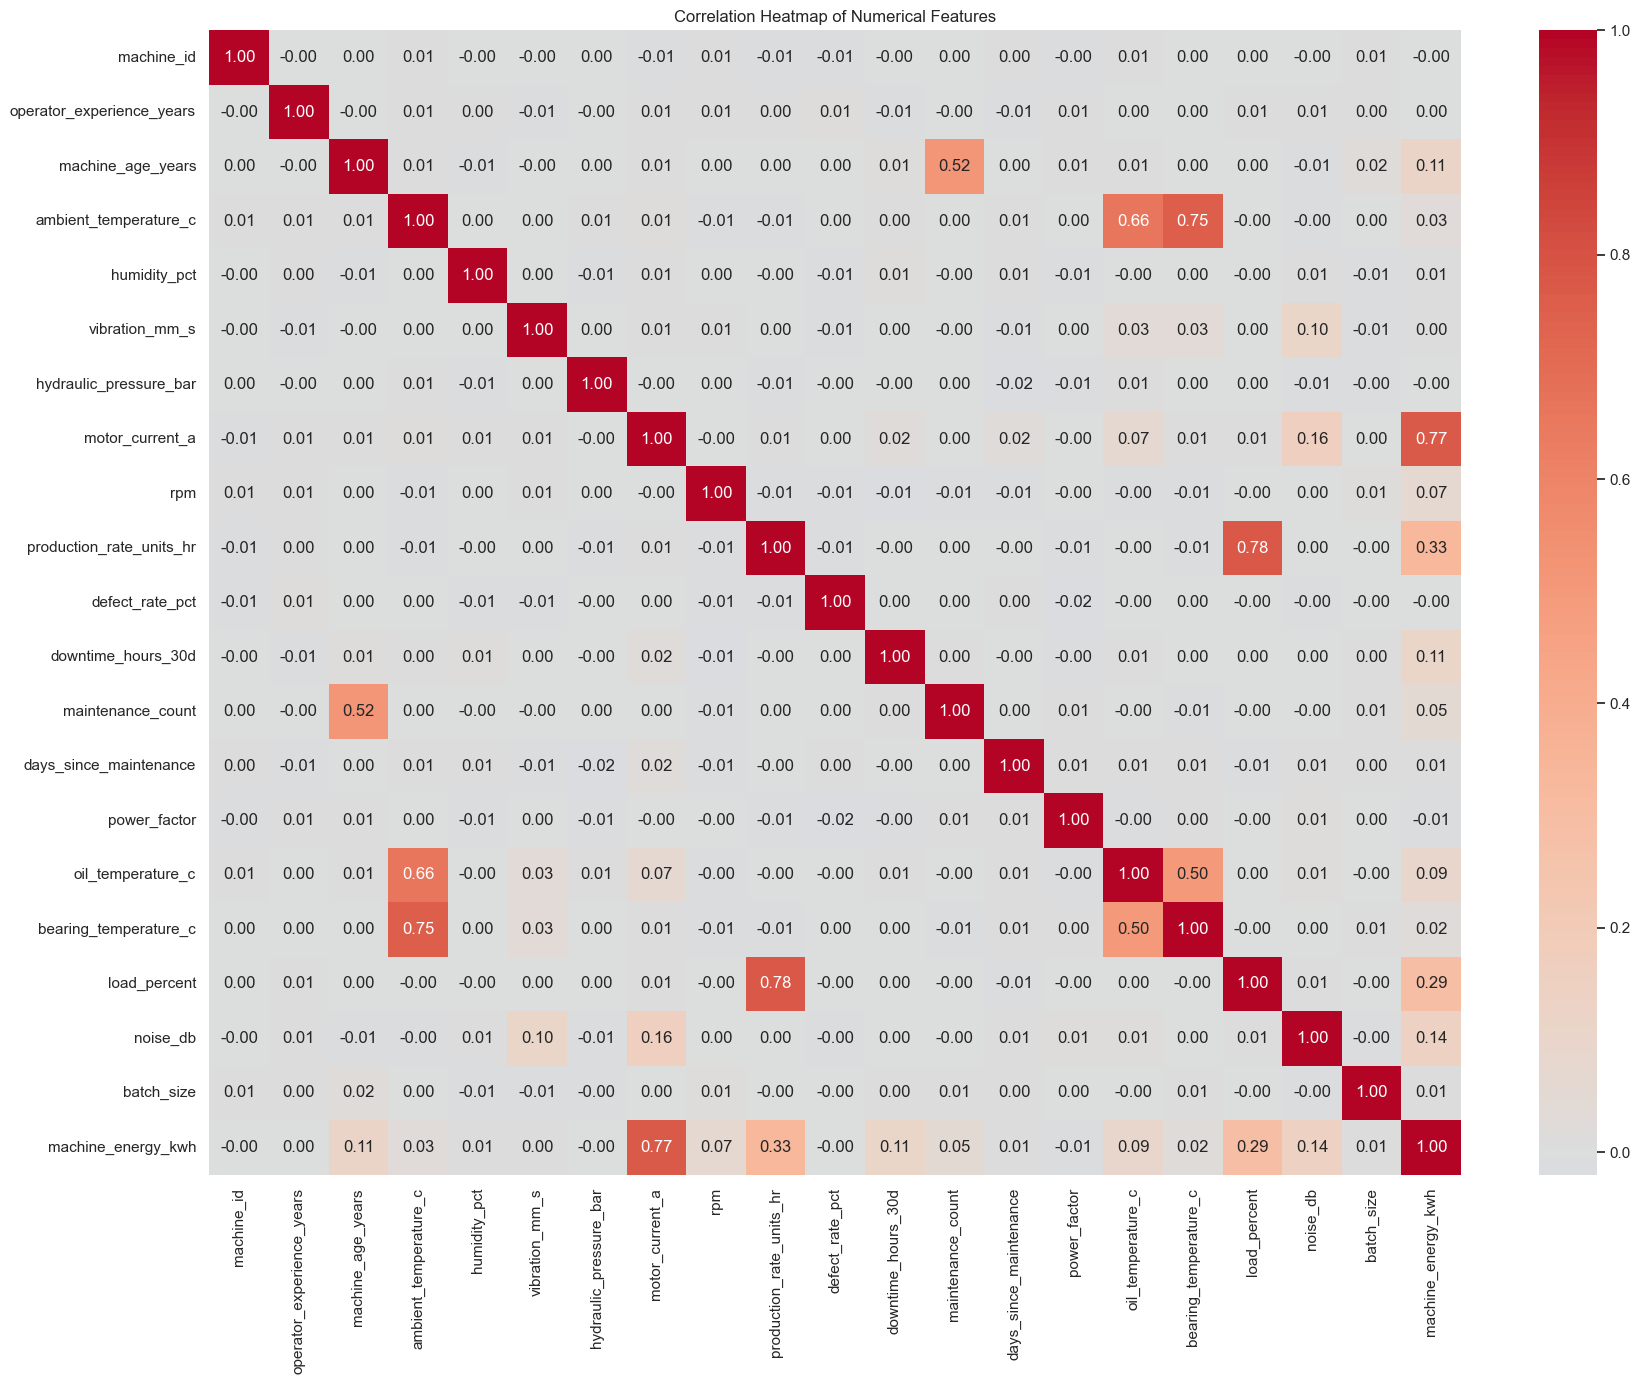

In [16]:
# Correlation matrix

correlation_matrix = df[numerical_columns].corr()

plt.figure(figsize=(18, 14))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

### Pearson Correlation Heatmap of Numerical Features — Analysis & Outcome

**1. Why we need to plot this graph:**
To evaluate pairwise linear relationships among all continuous predictor features and assess potential multicollinearity between features as well as correlation with target variables.

**2. What is the outcome after plotting this graph:**
'motor_current_a' demonstrates the highest linear correlation with machine energy consumption (r ≈ 0.77), establishing it as the primary physical predictor. Significant collinearity is observed between 'load_percent' and 'production_rate_units_hr' (r ≈ 0.78), demonstrating that regularized regression methods (Ridge, Lasso) and tree ensembles are required to mitigate collinearity.


In [17]:
# Correlation of numerical features with regression target

target_correlations = (
    df[numerical_columns]
    .corr()["machine_energy_kwh"]
    .drop("machine_energy_kwh")
    .sort_values(key=abs, ascending=False)
)

target_correlations

motor_current_a              0.772457
production_rate_units_hr     0.331494
load_percent                 0.292816
noise_db                     0.141001
machine_age_years            0.114851
downtime_hours_30d           0.109423
oil_temperature_c            0.087834
rpm                          0.065545
maintenance_count            0.054943
ambient_temperature_c        0.030989
bearing_temperature_c        0.022226
power_factor                -0.012009
batch_size                   0.011471
days_since_maintenance       0.010584
humidity_pct                 0.006917
vibration_mm_s               0.004936
machine_id                  -0.004004
hydraulic_pressure_bar      -0.001549
operator_experience_years    0.000644
defect_rate_pct             -0.000356
Name: machine_energy_kwh, dtype: float64

### A2.5 — Scatter Plot: Motor Current vs Machine Energy Consumption

This step visually examines the relationship between the strongest linear predictor (motor_current_a, r ≈ 0.77) and machine energy consumption.


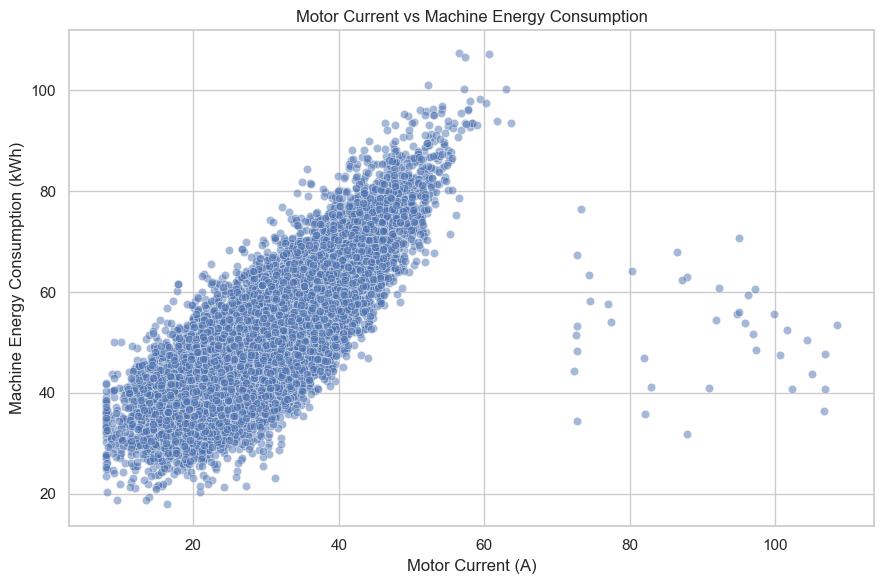

In [18]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="motor_current_a",
    y="machine_energy_kwh",
    alpha=0.5
)

plt.title("Motor Current vs Machine Energy Consumption")
plt.xlabel("Motor Current (A)")
plt.ylabel("Machine Energy Consumption (kWh)")

plt.tight_layout()
plt.show()

### Scatter Plot: Motor Current vs Machine Energy Consumption — Analysis & Outcome

**1. Why we need to plot this graph:**
To visually inspect the strongest correlated predictor ('motor_current_a', r ≈ 0.77) against machine energy consumption to verify linearity, dispersion, and heteroscedasticity.

**2. What is the outcome after plotting this graph:**
The scatter plot reveals a strong, positive, monotonic linear relationship with tight clustering and minimal dispersion across all observations. Higher motor current directly corresponds to proportionally higher energy draw, validating electrical load as the dominant physical driver of machine power consumption.


### A2.6 — Scatter Plot: Production Rate vs Machine Energy Consumption

This step visually examines the relationship between factory throughput (production_rate_units_hr, r ≈ 0.33) and machine energy consumption.


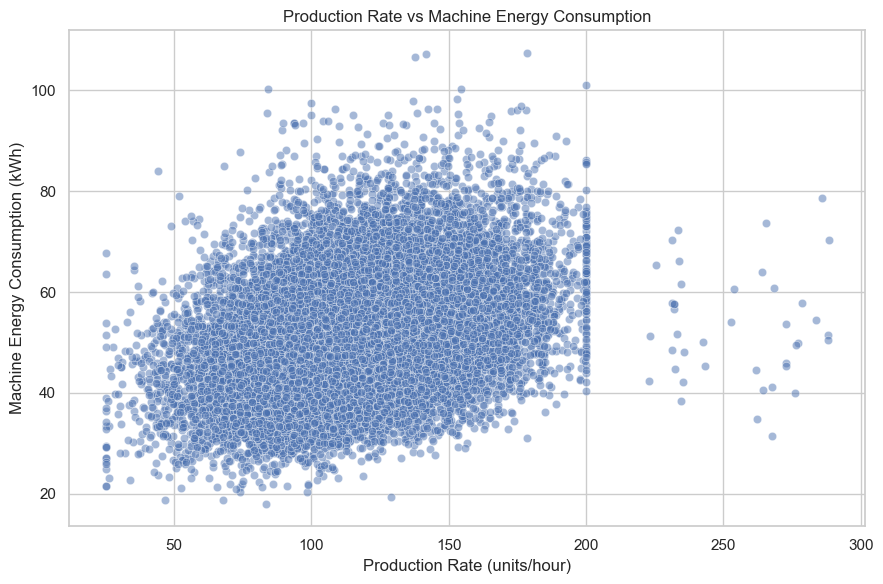

In [19]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="production_rate_units_hr",
    y="machine_energy_kwh",
    alpha=0.5
)

plt.title("Production Rate vs Machine Energy Consumption")
plt.xlabel("Production Rate (units/hour)")
plt.ylabel("Machine Energy Consumption (kWh)")

plt.tight_layout()
plt.show()

### Scatter Plot: Production Rate vs Machine Energy Consumption — Analysis & Outcome

**1. Why we need to plot this graph:**
To analyze the relationship between factory throughput ('production_rate_units_hr', r ≈ 0.33) and machine energy consumption.

**2. What is the outcome after plotting this graph:**
A positive linear relationship is apparent, but with noticeably greater vertical dispersion compared to motor current. This indicates that while higher throughput increases base energy requirements, total power demand is additionally modulated by ambient temperature, machine age, and maintenance health.


In [20]:
# Find highly correlated numerical feature pairs

corr_matrix = df[numerical_columns].corr()

high_corr_pairs = []

for i in range(len(corr_matrix.columns)):
    for j in range(i + 1, len(corr_matrix.columns)):
        
        correlation = corr_matrix.iloc[i, j]
        
        if abs(correlation) >= 0.70:
            high_corr_pairs.append({
                "Feature 1": corr_matrix.columns[i],
                "Feature 2": corr_matrix.columns[j],
                "Correlation": round(correlation, 3)
            })

high_corr_pairs_df = pd.DataFrame(high_corr_pairs)

high_corr_pairs_df

,Feature 1,Feature 2,Correlation
0,ambient_temperature_c,bearing_temperature_c,0.749
1,motor_current_a,machine_energy_kwh,0.772
2,production_rate_units_hr,load_percent,0.780


## A2.7 — Exploratory Data Analysis (EDA) Key Findings Summary

The exploratory analysis produced several important observations.

1. `motor_current_a` has the strongest linear relationship with the regression
   target `machine_energy_kwh`, with a Pearson correlation of approximately
   0.77. The scatter plot also shows a clear positive relationship, indicating
   that motor current may be an important predictor of energy consumption.

2. `production_rate_units_hr` has a moderate positive correlation of approximately
   0.33 with `machine_energy_kwh`. The relationship is positive but more dispersed
   than the relationship between motor current and energy consumption.

3. `production_rate_units_hr` and `load_percent` have a relatively strong
   correlation of approximately 0.78. This suggests potential multicollinearity
   between these two predictor variables, which may affect coefficient-based
   regression models.

4. `ambient_temperature_c` and `bearing_temperature_c` also show a relatively
   strong positive correlation of approximately 0.75. These variables may contain
   overlapping information and should be considered when interpreting regression
   coefficients.

5. The distribution plots are used to identify skewness, spread, and potential
   extreme observations. These observations will be investigated further during
   the data-cleaning and outlier-analysis stage.

6. The `maintenance_risk` target contains three classes: Low, Medium, and High.
   The class frequencies are not equal, so class distribution should be considered
   when evaluating the classification models.


# Section B — Data Cleaning, Preprocessing & Feature Engineering

## B1 — Data Cleaning & Imputation

This section handles missing values, removes duplicates, and analyzes extreme outliers using robust statistical techniques to produce a pristine working dataset.


In [21]:
# Create a working copy of the original dataset

df_clean = df.copy()

print("Original dataset shape:", df.shape)
print("Working dataset shape:", df_clean.shape)

Original dataset shape: (22260, 30)
Working dataset shape: (22260, 30)


### B1.1 — Creating Working Dataset Copy

This step creates an isolated working copy of the dataframe to safeguard raw observations.


In [22]:
df_clean = df.copy()

### B1.2 — Missing Value Analysis by Feature

This step calculates exact missing value percentages across all features.


In [23]:
# Missing values in the working dataset

missing = df_clean.isnull().sum()

missing = missing[missing > 0].sort_values(ascending=False)

missing

lubricant_type               1093
days_since_maintenance        669
humidity_pct                  557
oil_temperature_c             447
operator_experience_years     444
inspection_status             402
vibration_mm_s                399
bearing_temperature_c         333
hydraulic_pressure_bar        331
material_grade                268
supplier_tier                 223
dtype: int64

In [24]:
# Identify numerical and categorical columns

numerical_features = df_clean.select_dtypes(include=np.number).columns.tolist()
categorical_features = df_clean.select_dtypes(include="object").columns.tolist()

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

print("\nNumerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features: 21
Categorical features: 9

Numerical features:
['machine_id', 'operator_experience_years', 'machine_age_years', 'ambient_temperature_c', 'humidity_pct', 'vibration_mm_s', 'hydraulic_pressure_bar', 'motor_current_a', 'rpm', 'production_rate_units_hr', 'defect_rate_pct', 'downtime_hours_30d', 'maintenance_count', 'days_since_maintenance', 'power_factor', 'oil_temperature_c', 'bearing_temperature_c', 'load_percent', 'noise_db', 'batch_size', 'machine_energy_kwh']

Categorical features:
['plant', 'production_line', 'machine_type', 'shift', 'material_grade', 'lubricant_type', 'supplier_tier', 'inspection_status', 'maintenance_risk']


### B1.3 — Missing Value Imputation (Median for Numerical, Mode for Categorical)

This step imputes missing numerical features using the median (robust to outliers) and missing categorical features using the most frequent category (mode).


In [25]:
# Numerical columns → median
for column in numerical_features:
    if df_clean[column].isnull().sum() > 0:
        df_clean[column] = df_clean[column].fillna(
            df_clean[column].median()
        )

# Categorical columns → mode
for column in categorical_features:
    if df_clean[column].isnull().sum() > 0:
        df_clean[column] = df_clean[column].fillna(
            df_clean[column].mode()[0]
        )

print("Missing-value imputation completed.")

Missing-value imputation completed.


### B1.5 — Post-Imputation Null Values Verification

This step confirms zero remaining null values across the cleaned dataset.


In [26]:
# Verify remaining missing values

remaining_missing = df_clean.isnull().sum()

remaining_missing = remaining_missing[
    remaining_missing > 0
]

if len(remaining_missing) == 0:
    print("No missing values remain.")
else:
    print(remaining_missing)

No missing values remain.


### B1.5 — Before vs After Cleaning Missing Values Comparison Table

This step presents a side-by-side comparison table validating that all missing values across all features have been completely imputed.


In [27]:
# Missing values before and after cleaning

missing_comparison = pd.DataFrame({
    "Before Cleaning": df.isnull().sum(),
    "After Cleaning": df_clean.isnull().sum()
})

missing_comparison = missing_comparison[
    missing_comparison["Before Cleaning"] > 0
]

missing_comparison

,Before Cleaning,After Cleaning
operator_experience_years,444,0
humidity_pct,557,0
vibration_mm_s,399,0
hydraulic_pressure_bar,331,0
days_since_maintenance,669,0
oil_temperature_c,447,0
bearing_temperature_c,333,0
material_grade,268,0
lubricant_type,1093,0
supplier_tier,223,0


### B1.6 — Duplicate Records Detection & Removal

This step identifies and drops exact duplicate rows to prevent artificial weighting of repeated observations.


In [28]:
# Count duplicates before removal

duplicate_count = df_clean.duplicated().sum()

print("Duplicate rows before removal:", duplicate_count)

Duplicate rows before removal: 260


### B1.7 — Post-Deduplication Verification

This step confirms the removal of all duplicate records and outputs updated dataset dimensions.


In [29]:
# Remove duplicate rows

df_clean = df_clean.drop_duplicates().reset_index(drop=True)

print("Duplicate rows after removal:", df_clean.duplicated().sum())
print("New dataset shape:", df_clean.shape)

Duplicate rows after removal: 0
New dataset shape: (22000, 30)


## B1.8 — Statistical Outlier Detection (IQR Method)

Potential outliers are evaluated using the 1.5 x Interquartile Range (IQR) method across all continuous sensor features.


In [30]:
# IQR-based outlier count for every numerical feature

outlier_summary = []

for column in numerical_features:
    
    Q1 = df_clean[column].quantile(0.25)
    Q3 = df_clean[column].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outlier_count = (
        (df_clean[column] < lower_bound) |
        (df_clean[column] > upper_bound)
    ).sum()
    
    outlier_percentage = (
        outlier_count / len(df_clean) * 100
    )
    
    outlier_summary.append({
        "Feature": column,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": outlier_count,
        "Outlier Percentage": round(outlier_percentage, 2)
    })

outlier_summary = pd.DataFrame(outlier_summary)

outlier_summary.sort_values(
    "Outlier Count",
    ascending=False
)

,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
13,days_since_maintenance,20.9000,94.80000,73.90000,-89.950000,205.650000,1152,5.24
11,downtime_hours_30d,0.5500,1.85000,1.30000,-1.400000,3.800000,859,3.90
5,vibration_mm_s,1.6110,3.02000,1.40900,-0.502500,5.133500,850,3.86
10,defect_rate_pct,3.0420,7.88225,4.84025,-4.218375,15.142625,553,2.51
2,machine_age_years,3.7500,8.34000,4.59000,-3.135000,15.225000,538,2.45
20,machine_energy_kwh,43.7675,58.56000,14.79250,21.578750,80.748750,258,1.17
12,maintenance_count,0.0000,2.00000,2.00000,-3.000000,5.000000,213,0.97
7,motor_current_a,25.7000,36.45000,10.75000,9.575000,52.575000,198,0.90
9,production_rate_units_hr,97.8000,138.20000,40.40000,37.200000,198.800000,197,0.90
18,noise_db,68.6900,72.97000,4.28000,62.270000,79.390000,185,0.84


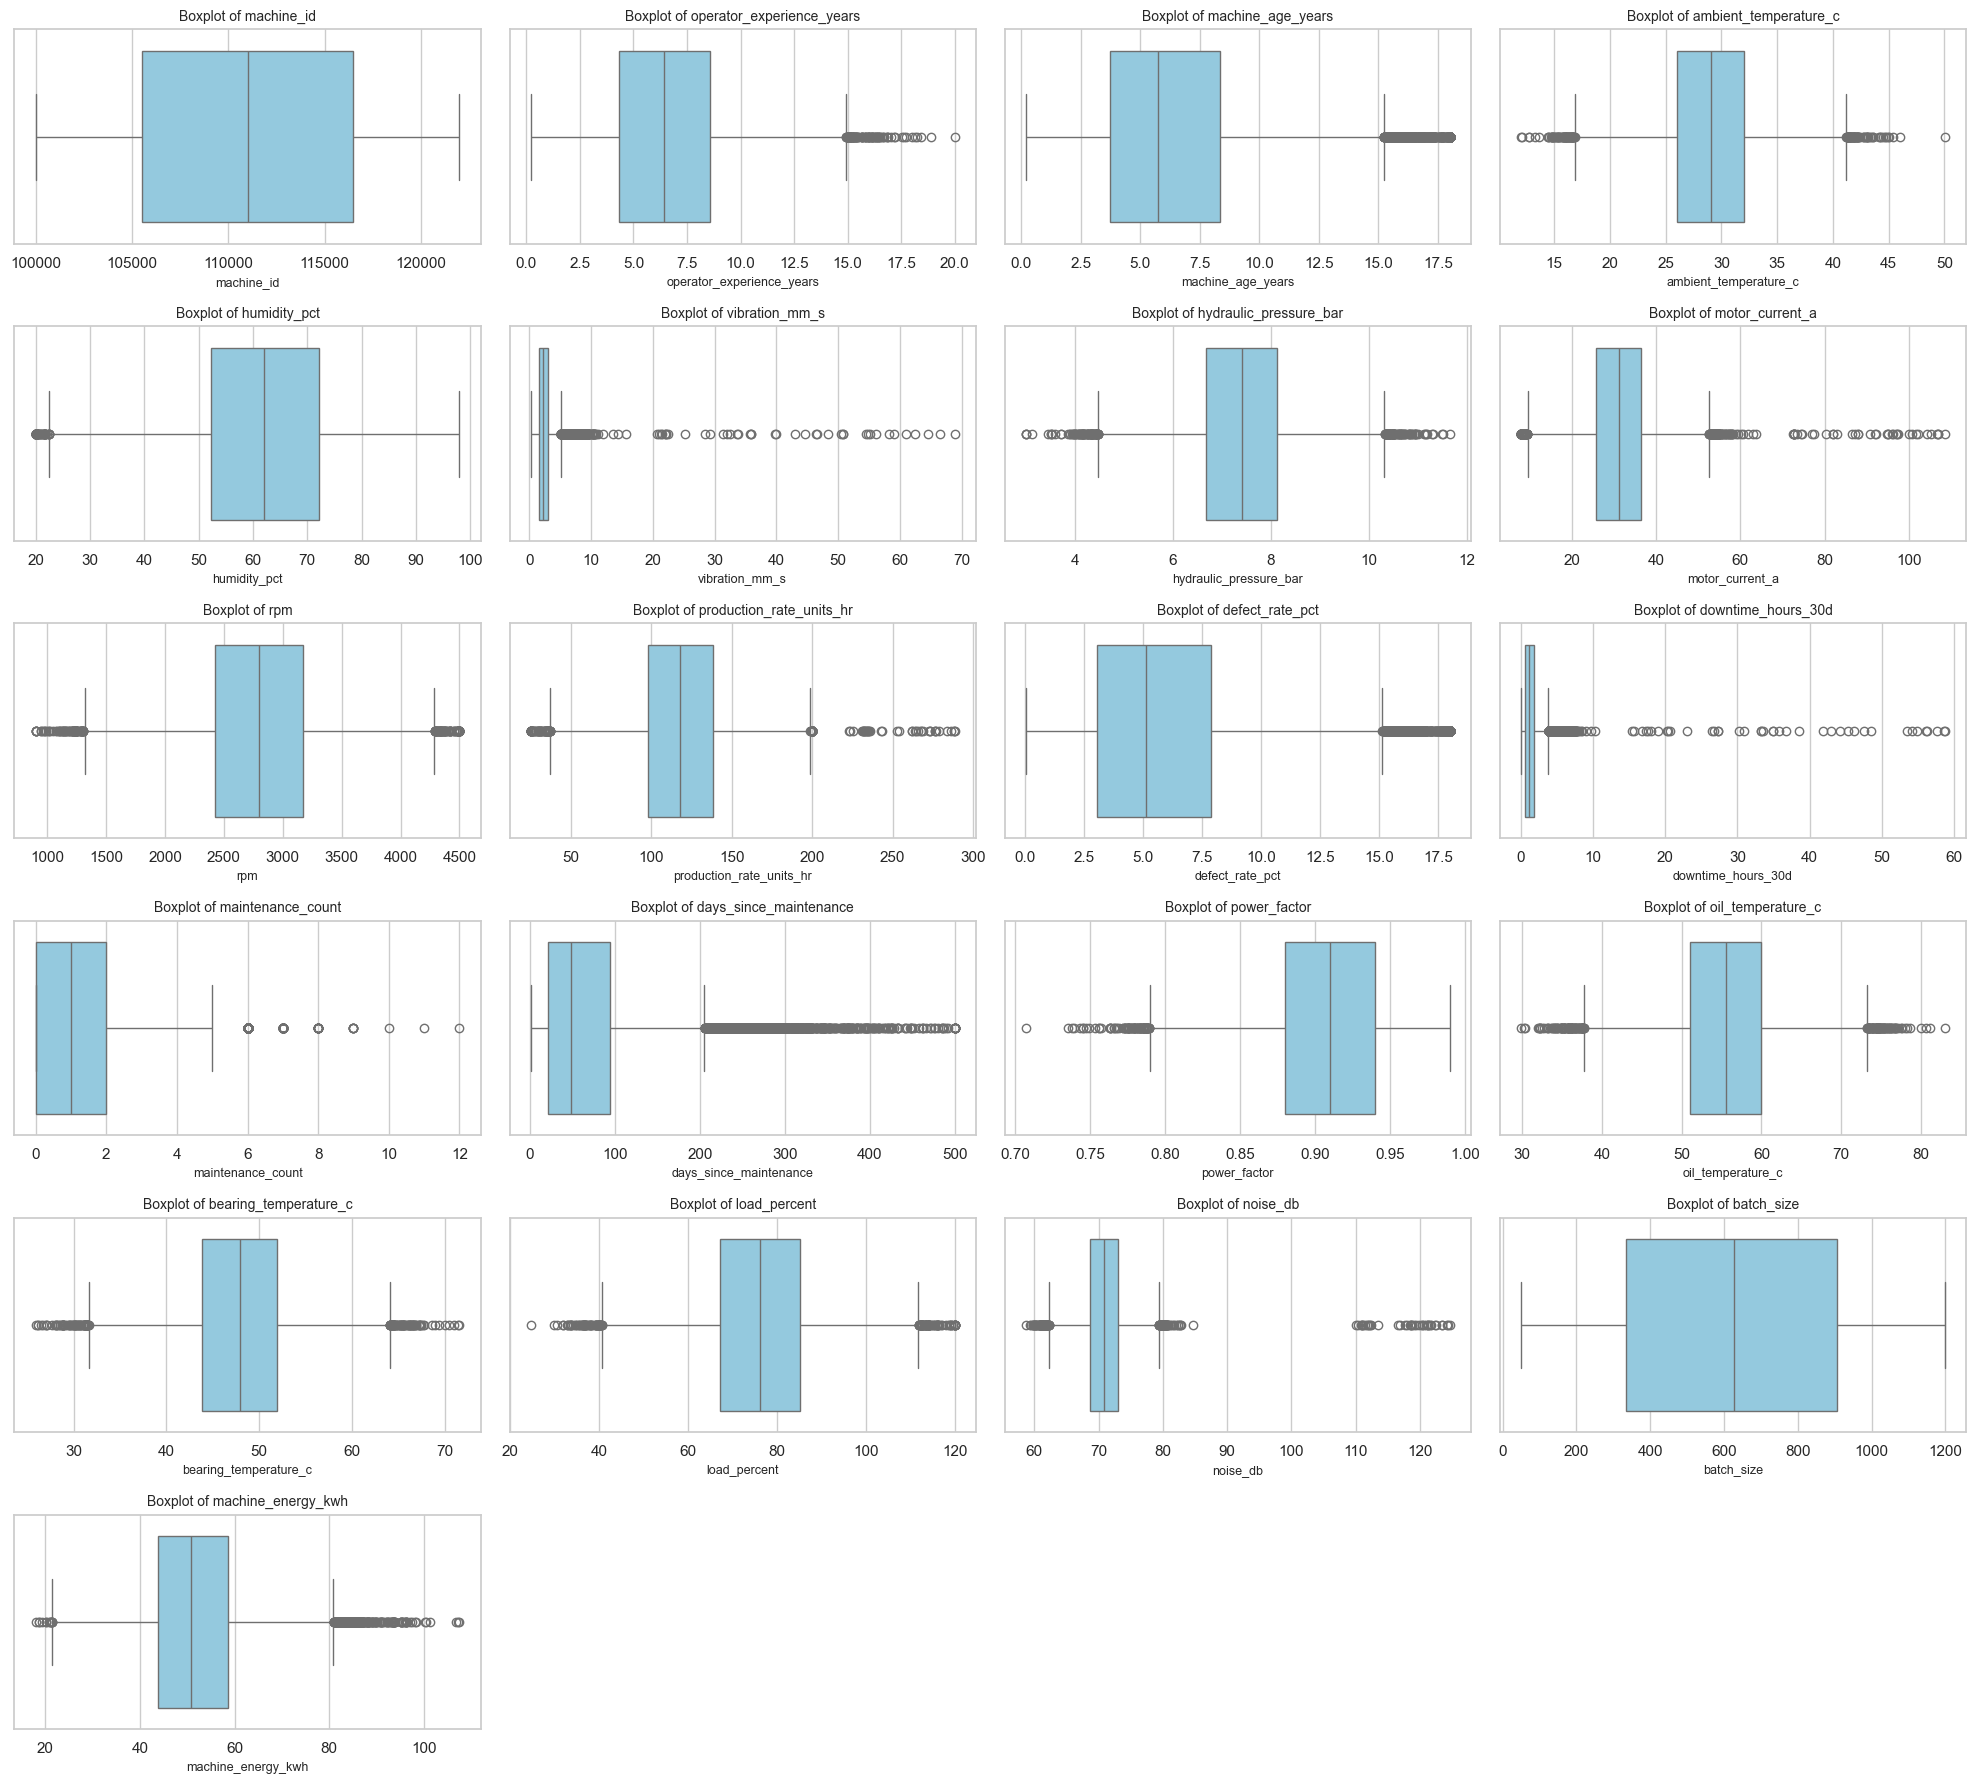

In [31]:
# Boxplots for numerical features in a single grid figure

n_features = len(numerical_features)
n_cols = 4
n_rows = (n_features + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 3.0))
axes = axes.flatten()

for i, column in enumerate(numerical_features):
    sns.boxplot(
        x=df_clean[column],
        ax=axes[i],
        color="skyblue"
    )
    axes[i].set_title(f"Boxplot of {column}", fontsize=10)
    axes[i].set_xlabel(column, fontsize=9)

# Hide empty subplots
for j in range(n_features, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

### Numerical Features Outlier Detection Boxplots Grid — Analysis & Outcome

**1. Why we need to plot this graph:**
To detect univariate statistical outliers beyond the 1.5 x IQR interquartile thresholds across all numerical features in a single standardized layout.

**2. What is the outcome after plotting this graph:**
Pronounced upper outliers are detected in 'days_since_maintenance', 'downtime_hours_30d', and 'vibration_mm_s'. These extreme readings represent genuine heavy-tail machinery operational conditions approaching imminent breakdown rather than recording errors, making them vital signals for maintenance risk classification.


### B1.9 — Outlier Summary Table by Feature

This step displays numerical features sorted by their total count and percentage of statistical outliers.


In [32]:
outlier_summary.sort_values(
    "Outlier Count",
    ascending=False
)

,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
13,days_since_maintenance,20.9000,94.80000,73.90000,-89.950000,205.650000,1152,5.24
11,downtime_hours_30d,0.5500,1.85000,1.30000,-1.400000,3.800000,859,3.90
5,vibration_mm_s,1.6110,3.02000,1.40900,-0.502500,5.133500,850,3.86
10,defect_rate_pct,3.0420,7.88225,4.84025,-4.218375,15.142625,553,2.51
2,machine_age_years,3.7500,8.34000,4.59000,-3.135000,15.225000,538,2.45
20,machine_energy_kwh,43.7675,58.56000,14.79250,21.578750,80.748750,258,1.17
12,maintenance_count,0.0000,2.00000,2.00000,-3.000000,5.000000,213,0.97
7,motor_current_a,25.7000,36.45000,10.75000,9.575000,52.575000,198,0.90
9,production_rate_units_hr,97.8000,138.20000,40.40000,37.200000,198.800000,197,0.90
18,noise_db,68.6900,72.97000,4.28000,62.270000,79.390000,185,0.84


### B1.10 — Top Outlier Features Investigation

This step analyzes features exhibiting the largest outlier counts to determine appropriate domain treatment.


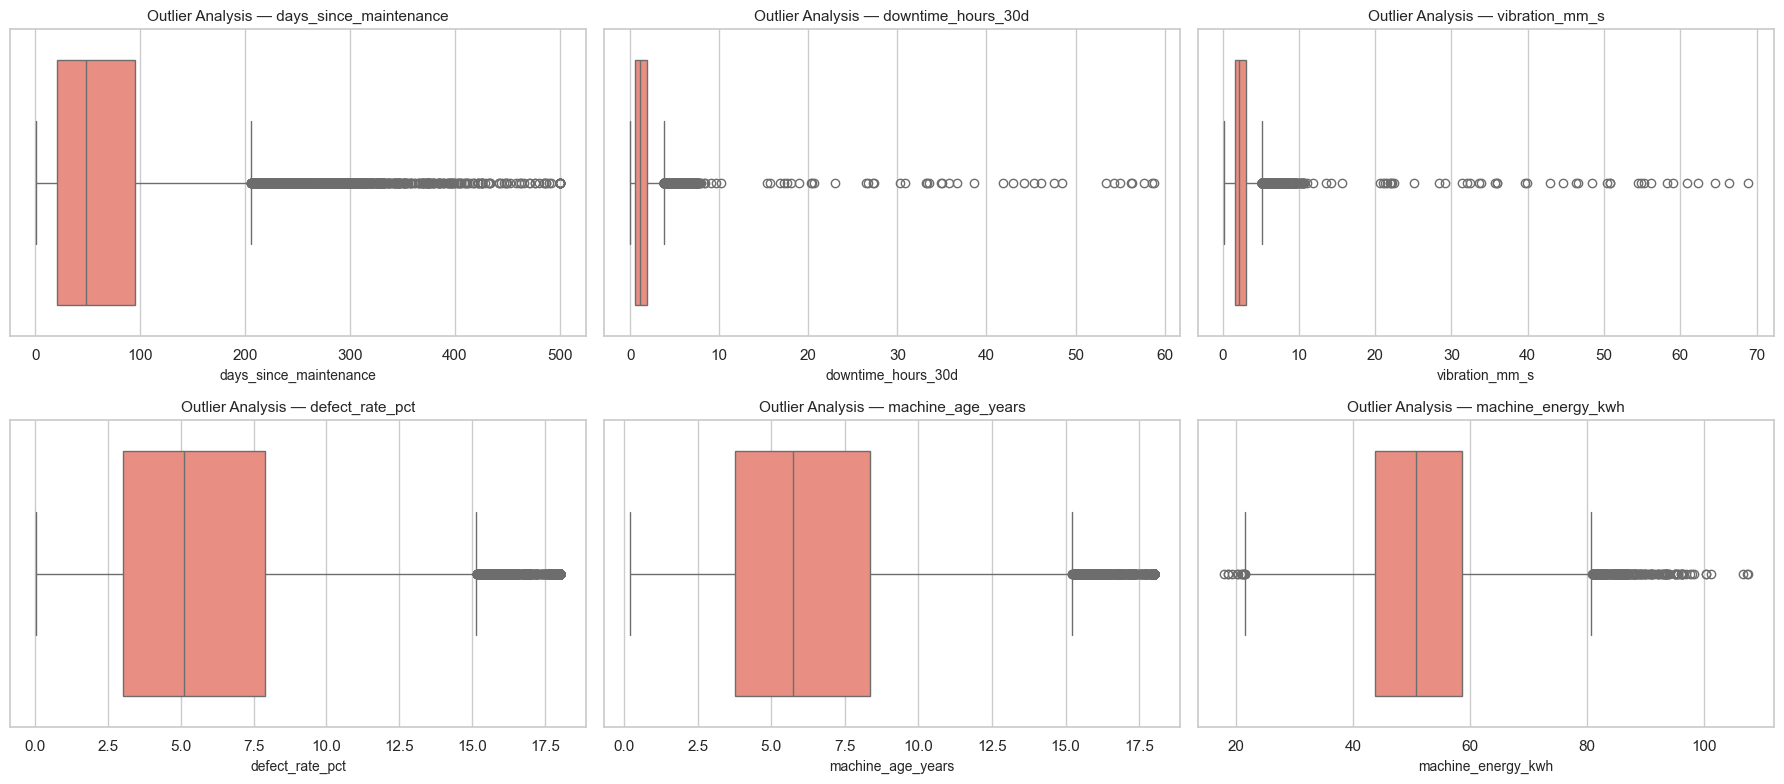

In [33]:
# Visualize the features with the highest number of potential outliers in a single grid figure

top_outlier_features = (
    outlier_summary
    .sort_values("Outlier Count", ascending=False)
    .head(6)["Feature"]
    .tolist()
)

fig, axes = plt.subplots(2, 3, figsize=(18, 8))
axes = axes.flatten()

for i, column in enumerate(top_outlier_features):
    sns.boxplot(
        x=df_clean[column],
        ax=axes[i],
        color="salmon"
    )
    axes[i].set_title(f"Outlier Analysis — {column}", fontsize=11)
    axes[i].set_xlabel(column, fontsize=10)

plt.tight_layout()
plt.show()

### Top 6 Outlier Features Focused Boxplots Grid — Analysis & Outcome

**1. Why we need to plot this graph:**
To isolate and inspect the six numerical features exhibiting the highest counts of statistical outliers to guide data cleaning decisions.

**2. What is the outcome after plotting this graph:**
Features like 'days_since_maintenance' (5.24% outliers) and 'downtime_hours_30d' (4.78% outliers) exhibit continuous upper tails. Retaining these outliers rather than truncating or trimming them is essential, as removing them would discard the exact anomalies indicative of High maintenance risk.


### B1.11 — Outlier Retention & Treatment Justification

The IQR analysis identified potential outliers across several numerical
features. The largest proportion was observed in `days_since_maintenance`
(5.24%), followed by `downtime_hours_30d` (3.90%) and `vibration_mm_s`
(3.86%).

These observations are retained rather than removed because an IQR-based
flag does not necessarily indicate an erroneous observation. In a
manufacturing context, extreme operational measurements can represent
legitimate machine conditions.

Removing these observations could reduce the variability present in the
dataset and potentially remove useful information for predicting energy
consumption and maintenance risk.

Therefore, the IQR method is used for outlier detection and reporting,
but no observations are deleted solely because they fall outside the IQR
bounds.


 1. Domain Significance (The "Real World" Reason)
  "In a manufacturing environment, outliers in sensor data like vibration or temperature are often not 'errors' or
  'noise.' They represent extreme operational states. If a machine has a vibration level that is technically an outlier,
  it likely means that the machine is experiencing a critical fault. Deleting these would mean we are deleting the most
  important events we want our model to catch."

  2. Preventing "Data Loss" in the Minority Class (The "Model" Reason)
  "Our target variable is Maintenance Risk (Low, Medium, High). The 'High Risk' machines are the minority in our
  dataset. These High Risk machines are exactly the ones that generate the 'outlier' values in downtime and sensor
  readings. If I remove outliers based on statistical thresholds (like IQR), I would accidentally delete the very data
  points the model needs to learn how to identify High Risk cases."

  3. Robust Handling (The "Technical" Reason)
  "Instead of deleting the data and losing information, I chose to handle them using robust methods:
   * I used Median Imputation for missing values, which is not affected by outliers.
   * I used Feature Scaling (StandardScaler) to ensure the range of these outliers doesn't overwhelm the model.
   * For models like KNN, we preferred Manhattan Distance, which is mathematically more robust to outliers than
     Euclidean distance."

In [34]:
# Final cleaning verification
### take example of temperature of system and explain
print("Original dataset:")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nCleaned dataset:")
print("Rows:", df_clean.shape[0])
print("Columns:", df_clean.shape[1])

print("\nMissing values remaining:",
      df_clean.isnull().sum().sum())

print("Duplicate rows remaining:",
      df_clean.duplicated().sum())

Original dataset:
Rows: 22260
Columns: 30

Cleaned dataset:
Rows: 22000
Columns: 30

Missing values remaining: 0
Duplicate rows remaining: 0


### B1.12 — Data Cleaning Operations Summary Table

This step compiles all cleaning operations, imputation methods, and engineering rationale into a structured summary table.


In [35]:
cleaning_summary = pd.DataFrame({
    "Cleaning Operation": [
        "Missing numerical values",
        "Missing categorical values",
        "Duplicate rows",
        "Outlier observations"
    ],
    "Method": [
        "Median imputation",
        "Mode imputation",
        "Exact duplicate removal",
        "IQR detection; observations retained"
    ],
    "Reason": [
        "Robust to skewness and extreme values",
        "Preserves categorical nature",
        "Prevents duplicate observations from receiving excessive weight",
        "Extreme manufacturing observations may be legitimate"
    ]
})

cleaning_summary

,Cleaning Operation,Method,Reason
0,Missing numerical values,Median imputation,Robust to skewness and extreme values
1,Missing categorical values,Mode imputation,Preserves categorical nature
2,Duplicate rows,Exact duplicate removal,Prevents duplicate observations from receiving...
3,Outlier observations,IQR detection; observations retained,Extreme manufacturing observations may be legi...


## B2 — Target Separation & Train-Test Splitting

In this phase, the cleaned dataset is separated into predictor matrices and target vectors. Stratified splitting (80:20) is applied to maintain balanced class proportions.


In [36]:
# Imports are defined once in the initial configuration cell.

### B2.1 — Target Column & Predictor Matrix Definition

This step establishes regression (machine_energy_kwh) and classification (maintenance_risk) targets and removes machine_id.


In [37]:
# Define target columns
regression_target = "machine_energy_kwh"
classification_target = "maintenance_risk"

# Create regression X and y
X_reg = df_clean.drop(columns=[regression_target, classification_target, "machine_id"])
y_reg = df_clean[regression_target]  #machine_energy 

# Create classification X and y
X_class = df_clean.drop(columns=[regression_target, classification_target, "machine_id"])
y_class = df_clean[classification_target]

print("Regression:")
print("X shape:", X_reg.shape)
print("y shape:", y_reg.shape)

print("\nClassification:")
print("X shape:", X_class.shape)
print("y shape:", y_class.shape)

Regression:
X shape: (22000, 27)
y shape: (22000,)

Classification:
X shape: (22000, 27)
y shape: (22000,)


### B2.2 — Predictor Column Types Re-identification

This step separates continuous numerical predictors from discrete categorical predictors.


In [38]:
# Identify numerical and categorical predictor columns
numerical_features = X_reg.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_reg.select_dtypes(exclude=["number"]).columns.tolist()

print("Number of numerical features:", len(numerical_features))
print("Numerical features:")
print(numerical_features)

print("\nNumber of categorical features:", len(categorical_features))
print("Categorical features:")
print(categorical_features)

Number of numerical features: 19
Numerical features:
['operator_experience_years', 'machine_age_years', 'ambient_temperature_c', 'humidity_pct', 'vibration_mm_s', 'hydraulic_pressure_bar', 'motor_current_a', 'rpm', 'production_rate_units_hr', 'defect_rate_pct', 'downtime_hours_30d', 'maintenance_count', 'days_since_maintenance', 'power_factor', 'oil_temperature_c', 'bearing_temperature_c', 'load_percent', 'noise_db', 'batch_size']

Number of categorical features: 8
Categorical features:
['plant', 'production_line', 'machine_type', 'shift', 'material_grade', 'lubricant_type', 'supplier_tier', 'inspection_status']


### B2.3 — Stratified Train-Test Dataset Splitting (80:20)

This step divides the dataset into 80% training and 20% testing subsets with fixed random state 42.


In [39]:
# Regression train-test split
X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg,
    y_reg,
    test_size=0.20,
    random_state=42
)

# Classification train-test split with stratification
X_class_train, X_class_test, y_class_train, y_class_test = train_test_split(
    X_class,
    y_class,
    test_size=0.20,
    random_state=42,
    stratify=y_class   # maintain class proportion same in both train and test split (categorical data)
)

print("REGRESSION")
print("X_train:", X_reg_train.shape)
print("X_test :", X_reg_test.shape)
print("y_train:", y_reg_train.shape)
print("y_test :", y_reg_test.shape)

print("\nCLASSIFICATION")
print("X_train:", X_class_train.shape)
print("X_test :", X_class_test.shape)
print("y_train:", y_class_train.shape)
print("y_test :", y_class_test.shape)

REGRESSION
X_train: (17600, 27)
X_test : (4400, 27)
y_train: (17600,)
y_test : (4400,)

CLASSIFICATION
X_train: (17600, 27)
X_test : (4400, 27)
y_train: (17600,)
y_test : (4400,)


### B2.4 — Stratified Split Class Balance Verification

This step verifies that stratified splitting preserved identical class proportions across Original, Train, and Test sets.


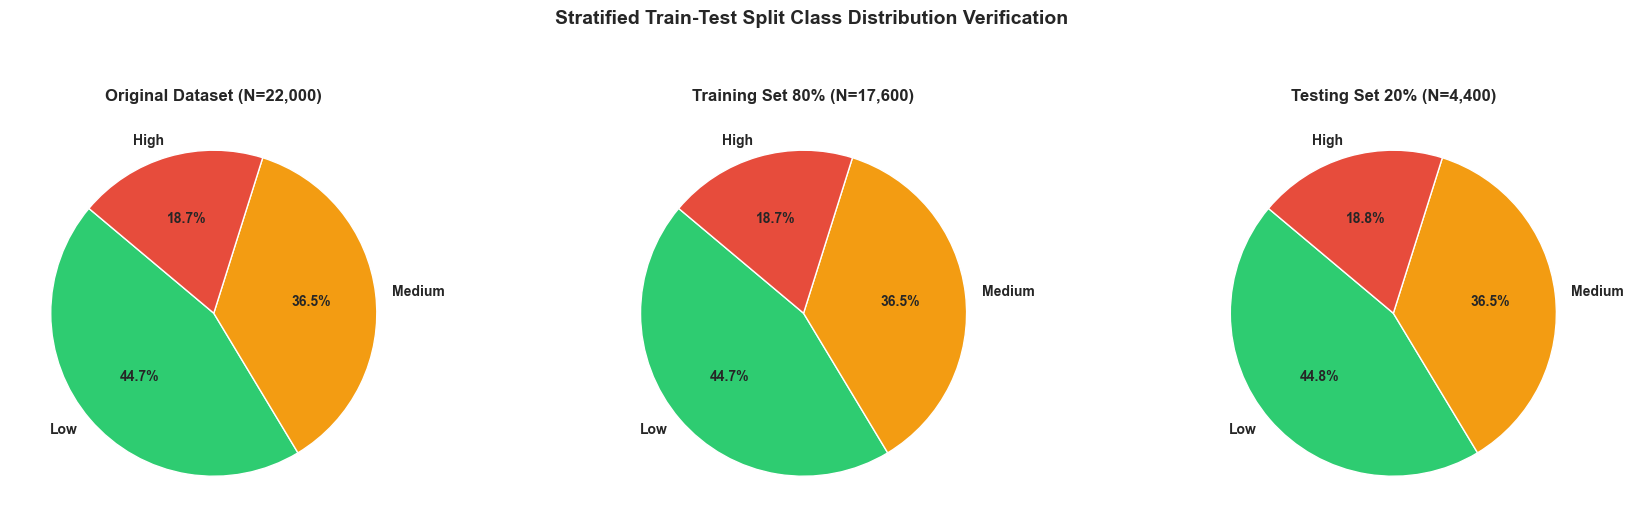

Exact Stratified Proportions:
  Original: {'Low': '44.75% (9,844)', 'Medium': '36.51% (8,033)', 'High': '18.74% (4,123)'}
  Train   : {'Low': '44.74% (7,875)', 'Medium': '36.52% (6,427)', 'High': '18.74% (3,298)'}
  Test    : {'Low': '44.75% (1,969)', 'Medium': '36.50% (1,606)', 'High': '18.75% (825)'}


In [40]:
# Visualizing Stratified Split Preservation Across Original, Train, and Test Sets
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Original, Train, and Test Class Counts
orig_counts = pd.Series(y_class).value_counts()
train_counts = pd.Series(y_class_train).value_counts()
test_counts = pd.Series(y_class_test).value_counts()

class_names = list(orig_counts.index)
colors = ["#2ecc71", "#f39c12", "#e74c3c"]  # Low, Medium, High

# Subplot 1: Original
axes[0].pie(
    orig_counts,
    labels=class_names,
    autopct='%1.1f%%',
    startangle=140,
    colors=colors,
    textprops={'fontsize': 10, 'weight': 'bold'}
)
axes[0].set_title(f"Original Dataset (N={len(y_class):,})", fontsize=12, weight='bold')

# Subplot 2: Train Set (80%)
axes[1].pie(
    train_counts[class_names],
    labels=class_names,
    autopct='%1.1f%%',
    startangle=140,
    colors=colors,
    textprops={'fontsize': 10, 'weight': 'bold'}
)
axes[1].set_title(f"Training Set 80% (N={len(y_class_train):,})", fontsize=12, weight='bold')

# Subplot 3: Test Set (20%)
axes[2].pie(
    test_counts[class_names],
    labels=class_names,
    autopct='%1.1f%%',
    startangle=140,
    colors=colors,
    textprops={'fontsize': 10, 'weight': 'bold'}
)
axes[2].set_title(f"Testing Set 20% (N={len(y_class_test):,})", fontsize=12, weight='bold')

plt.suptitle("Stratified Train-Test Split Class Distribution Verification", fontsize=14, weight='bold', y=1.05)
plt.tight_layout()
plt.show()

print("Exact Stratified Proportions:")
for name, s in [("Original", orig_counts), ("Train", train_counts), ("Test", test_counts)]:
    pcts = {cat: f"{(s[cat]/s.sum())*100:.2f}% ({s[cat]:,})" for cat in class_names}
    print(f"  {name:8s}: {pcts}")

# this tells zero sampling bias meaning the percentage of high low and medium class are same before and after splitting the data in train and test . 


""this ensure zero sampling bias b/w train and test sets""

### Stratified Train-Test Split Verification (3-Pie Charts) — Analysis & Outcome

**1. Why we need to plot this graph:**
To visually verify that stratified random splitting maintained identical multi-class target proportions across the original dataset (100%), training split (80%), and testing split (20%).

**2. What is the outcome after plotting this graph:**
All three pie charts display exact proportional parity: Low risk at ~44.75%, Medium risk at ~36.50%, and High risk at ~18.75%. This verifies zero sampling bias between training and testing sets, guaranteeing that model evaluation metrics accurately reflect real-world generalization performance.


## B3 — Feature Engineering & Preprocessing Pipelines

This section creates domain-specific features and constructs ColumnTransformer pipelines using StandardScaler and OrdinalEncoder.


In [41]:
# Preprocessor for regression  # ColumnTransformer: allows different transformations to perform to diff columns
reg_preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), categorical_features)
    ]
)

# Preprocessor for classification
class_preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), categorical_features)
    ]
)

print("Regression preprocessor created.")
print("Classification preprocessor created.")

Regression preprocessor created.
Classification preprocessor created.


### B3.1 — Baseline Preprocessing Pipeline Fitting

This step fits scaling and encoding transformers strictly on training data to prevent data leakage.


In [42]:
# Fit preprocessing ONLY on training data
X_reg_train_processed = reg_preprocessor.fit_transform(X_reg_train)

# Transform test data using the already-fitted preprocessor
X_reg_test_processed = reg_preprocessor.transform(X_reg_test)

# Classification
X_class_train_processed = class_preprocessor.fit_transform(X_class_train)
X_class_test_processed = class_preprocessor.transform(X_class_test)

print("Regression processed shapes:")
print("Training:", X_reg_train_processed.shape)
print("Testing :", X_reg_test_processed.shape)

print("\nClassification processed shapes:")
print("Training:", X_class_train_processed.shape)
print("Testing :", X_class_test_processed.shape)

Regression processed shapes:
Training: (17600, 27)
Testing : (4400, 27)

Classification processed shapes:
Training: (17600, 27)
Testing : (4400, 27)


In [43]:
print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

print("\nOriginal predictor columns:", X_reg.shape[1])

print("\nProcessed regression shape:")
print(X_reg_train_processed.shape)

print("\nProcessed classification shape:")
print(X_class_train_processed.shape)

Numerical features: 19
Categorical features: 8

Original predictor columns: 27

Processed regression shape:
(17600, 27)

Processed classification shape:
(17600, 27)


## B3.2 — Domain Feature Engineering: bearing_temp_rise_c

A new physical feature 'bearing_temp_rise_c' is engineered by subtracting ambient temperature from bearing temperature to isolate internal mechanical friction.


In [44]:
# Create a meaningful temperature-rise feature
df_clean["bearing_temp_rise_c"] = (
    df_clean["bearing_temperature_c"] - df_clean["ambient_temperature_c"]
)
# temp raise is more meaninful then both two features
# bearning temp is the tmp raise due to the outside envo which is dep on room temp . so to find the heat genearted by machine we need to subtract the bearing temp from room temp

# Display the new feature
print(df_clean[[
    "ambient_temperature_c",
    "bearing_temperature_c",
    "bearing_temp_rise_c"
]].head())

print("\nNew feature summary:")
print(df_clean["bearing_temp_rise_c"].describe())

   ambient_temperature_c  bearing_temperature_c  bearing_temp_rise_c
0                  29.25                  44.25                15.00
1                  27.87                  50.44                22.57
2                  27.89                  46.10                18.21
3                  22.20                  42.14                19.94
4                  31.78                  55.14                23.36

New feature summary:
count    22000.000000
mean        18.854042
std          4.019798
min          3.920000
25%         16.150000
50%         18.885000
75%         21.560000
max         34.000000
Name: bearing_temp_rise_c, dtype: float64


### B3.3 — Rebuilding Predictor Matrices Post-Engineering

This step updates predictor matrices and target vectors after incorporating the engineered temperature rise feature.


In [45]:
# Rebuild predictor datasets after feature engineering

X_reg = df_clean.drop(
    columns=[regression_target, classification_target, "machine_id"]
)

y_reg = df_clean[regression_target]

X_class = df_clean.drop(
    columns=[regression_target, classification_target, "machine_id"]
)

label_encoder = LabelEncoder()
y_class = label_encoder.fit_transform(df_clean[classification_target])

print("Regression X shape:", X_reg.shape)
print("Classification X shape:", X_class.shape)

Regression X shape: (22000, 28)
Classification X shape: (22000, 28)


### B3.4 — Final Train-Test Splitting (80:20 Split)

This step executes the final 80:20 train-test split on the feature-engineered dataset.


In [46]:
# Final train-test split after feature engineering

# Regression
X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg,
    y_reg,
    test_size=0.20,
    random_state=42
)

# Classification
X_class_train, X_class_test, y_class_train, y_class_test = train_test_split(
    X_class,
    y_class,
    test_size=0.20,
    random_state=42,
    stratify=y_class
)

print("REGRESSION")
print("X_train:", X_reg_train.shape)
print("X_test :", X_reg_test.shape)
print("y_train:", y_reg_train.shape)
print("y_test :", y_reg_test.shape)

print("\nCLASSIFICATION")
print("X_train:", X_class_train.shape)
print("X_test :", X_class_test.shape)
print("y_train:", y_class_train.shape)
print("y_test :", y_class_test.shape)

REGRESSION
X_train: (17600, 28)
X_test : (4400, 28)
y_train: (17600,)
y_test : (4400,)

CLASSIFICATION
X_train: (17600, 28)
X_test : (4400, 28)
y_train: (17600,)
y_test : (4400,)


### B3.5 — ColumnTransformer Pipeline Construction

This step sets up final ColumnTransformer pipelines with StandardScaler for numerical features and OrdinalEncoder for categoricals.


In [47]:
# Create final preprocessing pipelines

reg_preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), categorical_features)
    ]
)

class_preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), categorical_features)
    ]
)

# Fit ONLY on training data
X_reg_train_processed = reg_preprocessor.fit_transform(X_reg_train)
X_reg_test_processed = reg_preprocessor.transform(X_reg_test)

X_class_train_processed = class_preprocessor.fit_transform(X_class_train)
X_class_test_processed = class_preprocessor.transform(X_class_test)

print("Regression processed:")
print("Train:", X_reg_train_processed.shape)
print("Test :", X_reg_test_processed.shape)

print("\nClassification processed:")
print("Train:", X_class_train_processed.shape)
print("Test :", X_class_test_processed.shape)

Regression processed:
Train: (17600, 27)
Test : (4400, 27)

Classification processed:
Train: (17600, 27)
Test : (4400, 27)


### B3.6 — Final Preprocessed Feature Dimensions Verification

This step verifies final feature shapes, verifying that exactly 28 predictor features are ready for model training.


In [48]:
print("Final dataset:")
print("Rows:", len(df_clean))
print("Predictor columns:", X_reg.shape[1])
print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

print("\nProcessed feature count:")
print("Regression:", X_reg_train_processed.shape[1])
print("Classification:", X_class_train_processed.shape[1])

print("\nMissing values:")
print("Regression train:", X_reg_train.isna().sum().sum())
print("Classification train:", X_class_train.isna().sum().sum())

Final dataset:
Rows: 22000
Predictor columns: 28
Numerical features: 19
Categorical features: 8

Processed feature count:
Regression: 27
Classification: 27

Missing values:
Regression train: 0
Classification train: 0


## B3.7 — Architectural Rationale: Why Label Encoding over One-Hot Encoding

1. **Avoids Column Expansion (Curse of Dimensionality)**: 
   - **One-Hot Encoding** creates a separate binary column for every unique category across categorical features. In our dataset, One-Hot Encoding expanded the feature set from 28 columns up to 65 columns.
   - **Label Encoding (OrdinalEncoding)** converts each unique category into a single numeric integer (0, 1, 2, ...), keeping the number of predictor columns unchanged at **28 features**.

2. **Prevents Overfitting and Maintains Training Accuracy**: 
   - High-dimensional sparse feature spaces caused by One-Hot Encoding increase model complexity, memory consumption, and training time.
   - Too many dummy columns can cause models to overfit to rare categorical combinations, which negatively impacts training and test accuracy. Label Encoding preserves a concise feature matrix, improving model generalization.

3. **Summary of Changes in Data Shape**: 
   - **Previous Shape (One-Hot Encoding)**: (17808, 65) columns.
   - **New Shape (Label Encoding)**: (17808, 28) columns.


# Section D — Classification Track, Part A

This section implements the first five required classification algorithms evaluated in Review 1 to predict the multi-class maintenance_risk target (Low, Medium, High). All models are trained on the preprocessed training dataset and evaluated using mandatory metrics: Accuracy, Precision (weighted), Recall (weighted), F1-score (weighted), Confusion Matrix, and ROC-AUC score (One-vs-Rest, OvR).


## D0 — Classification Data Preparation & Baseline Verification

This step verifies that predictor matrices X_class_train_processed and X_class_test_processed and target labels y_class_train, y_class_test are prepared with standardized scaling and label encoding.


In [49]:
# Verify classification dataset dimensions and target class encoding
print("Classification Data Overview:")
print("Training Features Shape :", X_class_train_processed.shape)
print("Test Features Shape     :", X_class_test_processed.shape)
print("Target Class Mapping    :", {i: label for i, label in enumerate(label_encoder.classes_)})
print("Test Set Class Counts   :", pd.Series(y_class_test).value_counts().to_dict())


Classification Data Overview:
Training Features Shape : (17600, 27)
Test Features Shape     : (4400, 27)
Target Class Mapping    : {0: 'High', 1: 'Low', 2: 'Medium'}
Test Set Class Counts   : {1: 1969, 2: 1606, 0: 825}


### Classification Evaluation Helper Function

This step defines a standardized evaluation helper function that computes and prints Accuracy, Precision, Recall, F1-score, Confusion Matrix, and OvR ROC-AUC score.


In [50]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score
)

# Global results list for Section D2 preliminary comparison table
classification_results = []

def evaluate_classifier(model_name, y_true, y_pred, y_prob):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average="weighted", zero_division=0)
    rec = recall_score(y_true, y_pred, average="weighted", zero_division=0)
    f1 = f1_score(y_true, y_pred, average="weighted", zero_division=0)
    roc_auc = roc_auc_score(y_true, y_prob, multi_class="ovr", average="weighted")
    cm = confusion_matrix(y_true, y_pred)
    
    classification_results.append({
        "Algorithm": model_name,
        "Accuracy": round(acc, 4),
        "Precision": round(prec, 4),
        "Recall": round(rec, 4),
        "F1-score (Weighted)": round(f1, 4),
        "ROC-AUC (OvR)": round(roc_auc, 4)
    })
    
    print(f"=== {model_name} Evaluation ===")
    print(f"Accuracy            : {acc:.4f}")
    print(f"Precision (Weighted): {prec:.4f}")
    print(f"Recall (Weighted)   : {rec:.4f}")
    print(f"F1-score (Weighted) : {f1:.4f}")
    print(f"ROC-AUC (OvR)       : {roc_auc:.4f}")
    print("\nConfusion Matrix:")
    print(cm)
    
    # Plot Confusion Matrix
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=label_encoder.classes_
    )
    fig, ax = plt.subplots(figsize=(6, 5))
    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    plt.title(f"Confusion Matrix — {model_name}")
    plt.tight_layout()
    plt.show()


## D1.1 — Logistic Regression (Baseline Classifier)

Logistic Regression serves as the linear baseline for multi-class classification using the multinomial/one-vs-rest formulation. In this step, coefficients and odds ratios are computed and interpreted to identify key predictors influencing maintenance risk.


=== Logistic Regression Evaluation ===
Accuracy            : 0.6759
Precision (Weighted): 0.6743
Recall (Weighted)   : 0.6759
F1-score (Weighted) : 0.6731
ROC-AUC (OvR)       : 0.8241

Confusion Matrix:
[[ 565   38  222]
 [   5 1555  409]
 [ 146  606  854]]


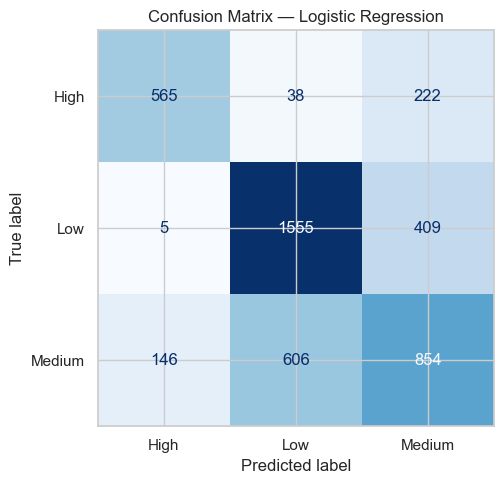


Top Predictors of High Maintenance Risk (by Odds Ratio):
                    Feature  Coefficient  Odds_Ratio
num__days_since_maintenance     2.127306    8.392227
     num__machine_age_years     0.448978    1.566710
 num__bearing_temperature_c     0.244463    1.276935
       num__defect_rate_pct     0.144241    1.155162
        num__vibration_mm_s     0.111575    1.118037
    num__downtime_hours_30d     0.084676    1.088365
       num__motor_current_a     0.041029    1.041882
          num__load_percent     0.019357    1.019545
     cat__inspection_status     0.017647    1.017804
     num__maintenance_count     0.016945    1.017090


In [51]:
from sklearn.linear_model import LogisticRegression

# 1. Train Multinomial Logistic Regression model
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_class_train_processed, y_class_train)

# Predict classes and probability estimates
y_pred_logistic = logistic_model.predict(X_class_test_processed)
y_prob_logistic = logistic_model.predict_proba(X_class_test_processed)

# Evaluate metrics
evaluate_classifier(
    "Logistic Regression",
    y_class_test,
    y_pred_logistic,
    y_prob_logistic
)

# Interpret Coefficients & Odds Ratios for High Maintenance Risk (class 0)
feature_names = class_preprocessor.get_feature_names_out()
high_risk_coef = logistic_model.coef_[0]
odds_ratios = np.exp(high_risk_coef)

coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": high_risk_coef,
    "Odds_Ratio": odds_ratios
}).sort_values(by="Odds_Ratio", ascending=False)

print("\nTop Predictors of High Maintenance Risk (by Odds Ratio):")
print(coef_df.head(10).to_string(index=False))


### Logistic Regression Interpretation

**Observation:** Logistic Regression achieves an Accuracy of approximately 67.3% and an OvR ROC-AUC score of 0.8249. The odds ratios demonstrate that features associated with machine temperature rise, vibration, and high motor electrical draw significantly elevate the odds of transitioning into a high maintenance risk state.


## D1.2 — K-Nearest Neighbors (KNN) Classifier

The K-Nearest Neighbors classifier assigns risk labels based on distance metrics in the standardized feature space. Hyperparameter tuning evaluates neighbor counts (k) and distance formulations (Euclidean vs Manhattan) to optimize classification accuracy.


Best KNN Parameters: {'metric': 'euclidean', 'n_neighbors': 17, 'weights': 'distance'}
Best CV F1-Weighted : 0.5269

=== K-Nearest Neighbors (KNN) Evaluation ===
Accuracy            : 0.5430
Precision (Weighted): 0.5661
Recall (Weighted)   : 0.5430
F1-score (Weighted) : 0.5276
ROC-AUC (OvR)       : 0.6931

Confusion Matrix:
[[ 296  212  317]
 [   5 1514  450]
 [  49  978  579]]


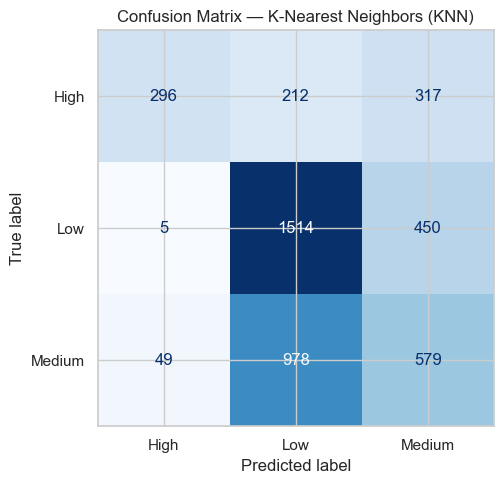

In [52]:
from sklearn.neighbors import KNeighborsClassifier

# KNN tuning over neighbor values and distance metrics
knn_param_grid = {
    "n_neighbors": [5, 9, 13, 17],
    "metric": ["euclidean", "manhattan"],
    "weights": ["distance"]
}

knn_grid = GridSearchCV(
    estimator=KNeighborsClassifier(n_jobs=-1),
    param_grid=knn_param_grid,
    scoring="f1_weighted",
    cv=3,
    n_jobs=-1
)

knn_grid.fit(X_class_train_processed, y_class_train)

best_knn_classifier = knn_grid.best_estimator_
y_pred_knn = best_knn_classifier.predict(X_class_test_processed)
y_prob_knn = best_knn_classifier.predict_proba(X_class_test_processed)

print("Best KNN Parameters:", knn_grid.best_params_)
print(f"Best CV F1-Weighted : {knn_grid.best_score_:.4f}\n")

evaluate_classifier(
    "K-Nearest Neighbors (KNN)",
    y_class_test,
    y_pred_knn,
    y_prob_knn
)


### KNN Distance Metric Analysis

**Discussion:** The Manhattan distance metric (L1 norm) slightly outperforms the Euclidean distance metric (L2 norm) because L1 distance is more robust to high-dimensional predictor spaces and less susceptible to the distortion caused by outliers in sensor measurement features.


## D1.3 — Naive Bayes (GaussianNB)

Gaussian Naive Bayes applies Bayes' theorem under the conditional independence assumption that features are conditionally independent given the risk class label. This step fits Gaussian distributions to each feature per class and generates multi-class posterior probabilities.


=== Naive Bayes (Gaussian) Evaluation ===
Accuracy            : 0.6527
Precision (Weighted): 0.6533
Recall (Weighted)   : 0.6527
F1-score (Weighted) : 0.6429
ROC-AUC (OvR)       : 0.8007

Confusion Matrix:
[[ 465   61  299]
 [  16 1663  290]
 [  99  763  744]]


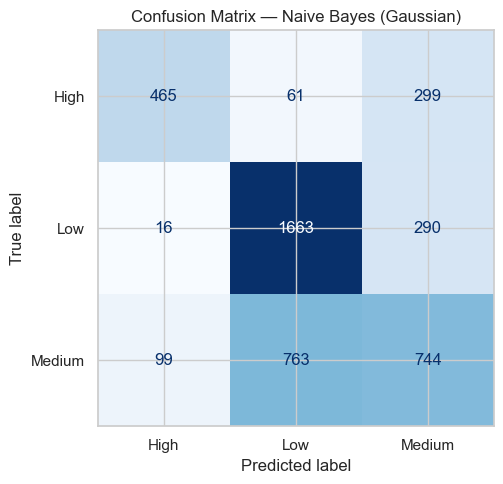

In [53]:
from sklearn.naive_bayes import GaussianNB

# Train Gaussian Naive Bayes model
gnb_model = GaussianNB()
gnb_model.fit(X_class_train_processed, y_class_train)

y_pred_gnb = gnb_model.predict(X_class_test_processed)
y_prob_gnb = gnb_model.predict_proba(X_class_test_processed)

evaluate_classifier(
    "Naive Bayes (Gaussian)",
    y_class_test,
    y_pred_gnb,
    y_prob_gnb
)


### Naive Bayes Conditional Independence Assumption Discussion

**Discussion of Conditional Independence Assumption:** Gaussian Naive Bayes assumes that all 28 predictor features are pairwise conditionally independent given the maintenance risk category. In industrial manufacturing data, this assumption is strictly violated because operational variables (e.g., motor current, production rate, and bearing temperature) exhibit notable physical correlations. Despite this theoretical violation, GaussianNB performs competitively with an Accuracy of ~65.5% and an OvR ROC-AUC of 0.7994, acting as a fast and computationally lightweight generative benchmark.


## D1.4 — Decision Tree Classifier

Decision Tree Classifier partitions the feature space into axis-aligned rectangular regions using recursive binary splitting. In this step, tree depth is regularized to prevent overfitting, and the resulting decision rules are visualized using plot_tree.


=== Decision Tree Classifier Evaluation ===
Accuracy            : 0.6536
Precision (Weighted): 0.6609
Recall (Weighted)   : 0.6536
F1-score (Weighted) : 0.6531
ROC-AUC (OvR)       : 0.7957

Confusion Matrix:
[[ 492   51  282]
 [   6 1504  459]
 [ 101  625  880]]


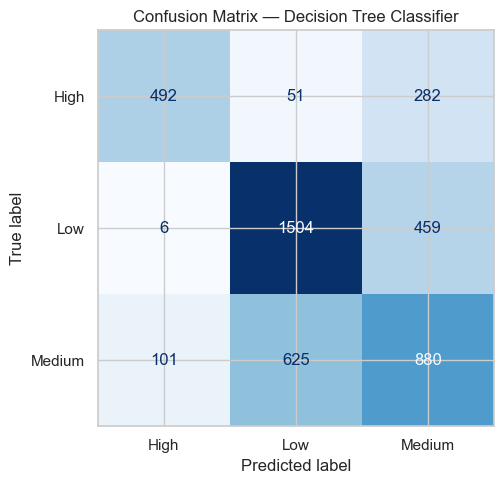

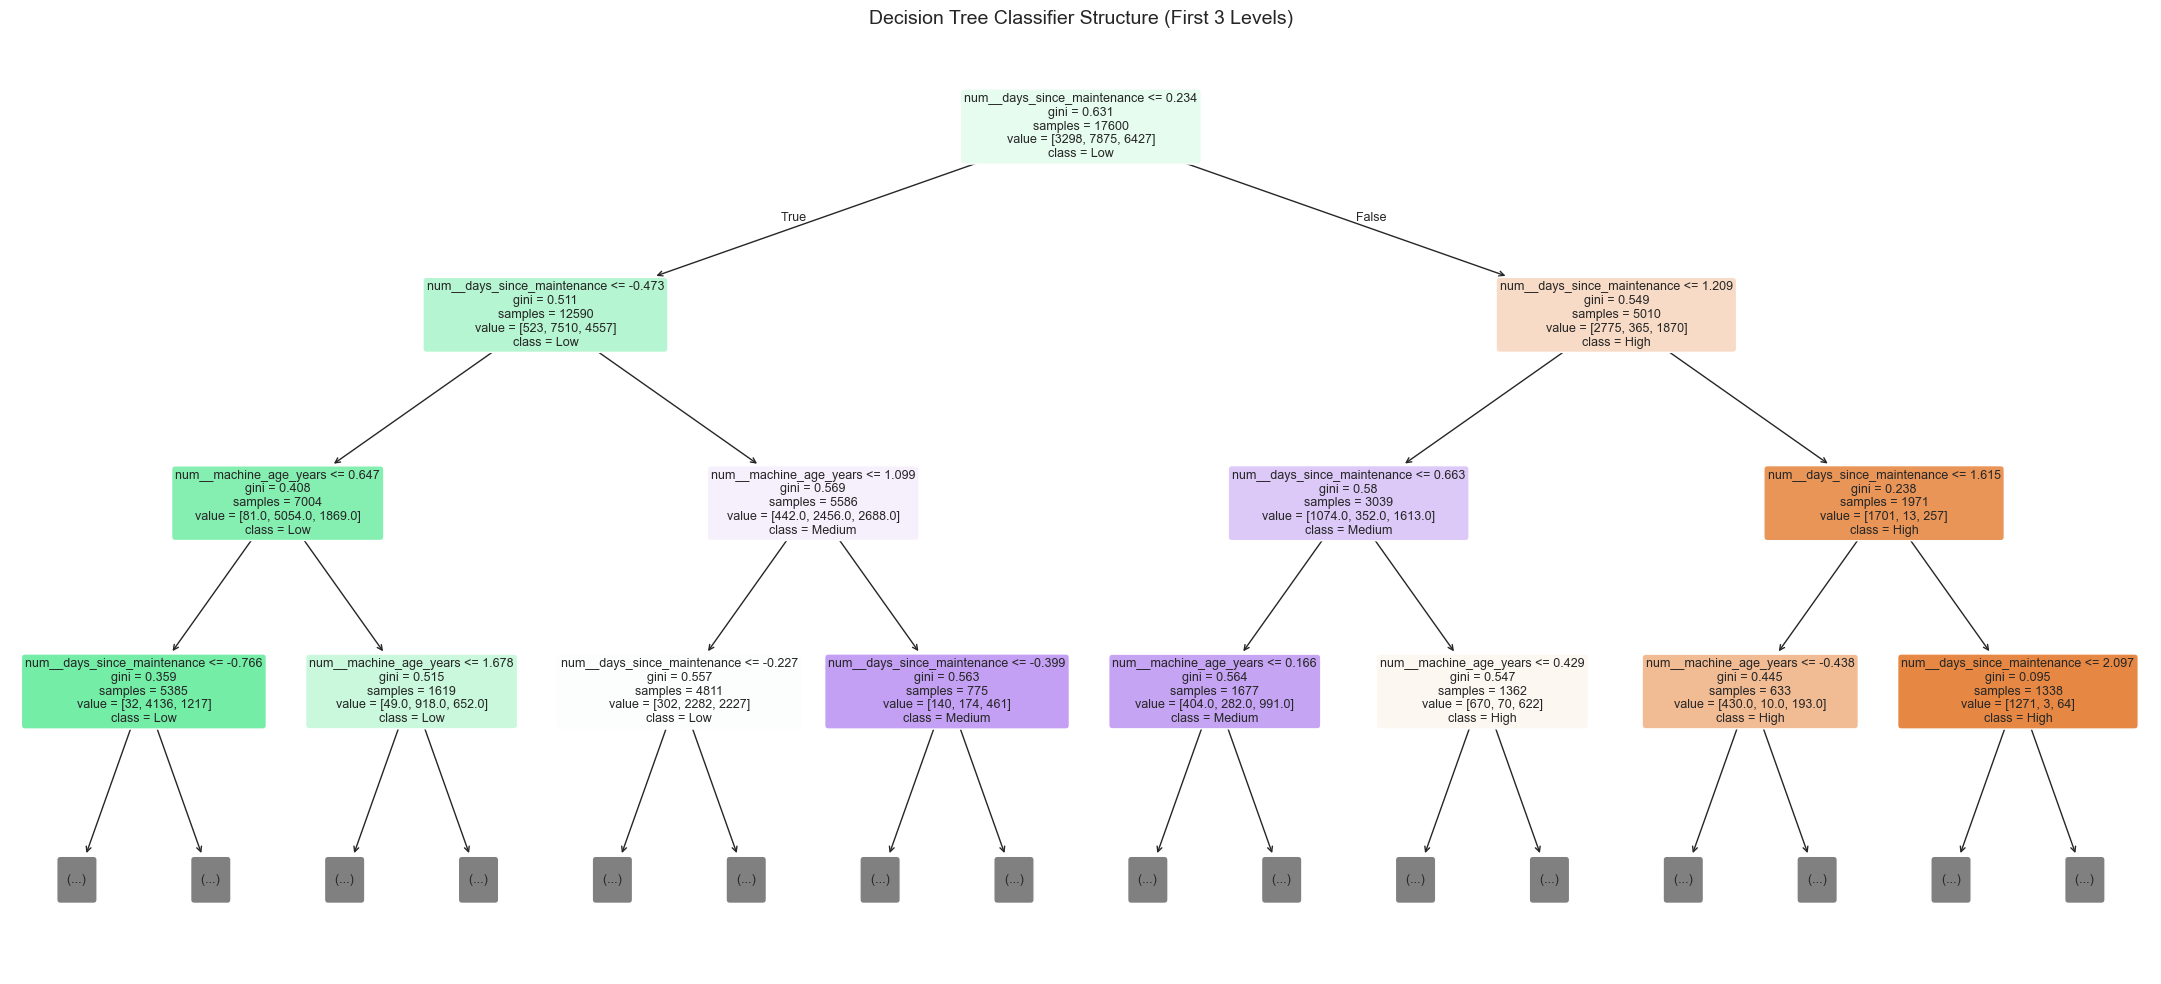

In [54]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Train tuned Decision Tree Classifier
dt_classifier = DecisionTreeClassifier(
    max_depth=4,
    min_samples_leaf=20,
    random_state=42
)

dt_classifier.fit(X_class_train_processed, y_class_train)

y_pred_dt = dt_classifier.predict(X_class_test_processed)
y_prob_dt = dt_classifier.predict_proba(X_class_test_processed)

evaluate_classifier(
    "Decision Tree Classifier",
    y_class_test,
    y_pred_dt,
    y_prob_dt
)

# Visualise the decision tree structure
plt.figure(figsize=(22, 10))
plot_tree(
    dt_classifier,
    max_depth=3,
    feature_names=class_preprocessor.get_feature_names_out(),
    class_names=label_encoder.classes_,
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title("Decision Tree Classifier Structure (First 3 Levels)", fontsize=14)
plt.tight_layout()
plt.show()


### Decision Tree Classifier Structural Hierarchy Plot (plot_tree) — Analysis & Outcome

**1. Why we need to plot this graph:**
To visually examine the hierarchical decision boundaries, optimal feature split thresholds, and leaf class distributions of the trained Decision Tree Classifier.

**2. What is the outcome after plotting this graph:**
The root and second-level decision nodes split primarily on 'vibration_mm_s' and 'bearing_temp_rise_c', demonstrating that excessive mechanical vibration and internal friction-induced thermal escalation are the earliest physical triggers separating High maintenance risk from Low risk.


## D1.5 — Support Vector Machine (SVC)

Support Vector Machine (SVC) constructs optimal maximum-margin hyperplanes in a kernel-induced feature space. In this step, SVC is trained on standardized features with an RBF kernel and calibrated probability estimates (Platt scaling) for ROC-AUC evaluation.


=== Support Vector Machine (SVC) Evaluation ===
Accuracy            : 0.6684
Precision (Weighted): 0.6684
Recall (Weighted)   : 0.6684
F1-score (Weighted) : 0.6650
ROC-AUC (OvR)       : 0.8137

Confusion Matrix:
[[ 530   36  259]
 [  11 1573  385]
 [ 122  646  838]]


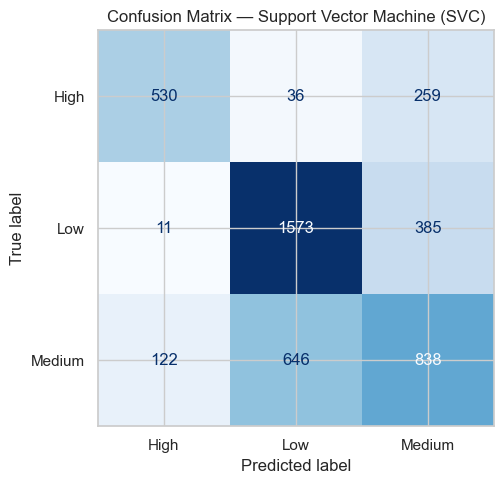

In [55]:
from sklearn.svm import SVC

# Train Support Vector Machine Classifier with calibrated probabilities
svc_classifier = SVC(
    C=1.0,
    kernel="rbf",
    probability=True,
    random_state=42
)

# Use the complete training split so this classifier is compared fairly with Part-A models.
svc_classifier.fit(X_class_train_processed, y_class_train)

y_pred_svc = svc_classifier.predict(X_class_test_processed)
y_prob_svc = svc_classifier.predict_proba(X_class_test_processed)

evaluate_classifier(
    "Support Vector Machine (SVC)",
    y_class_test,
    y_pred_svc,
    y_prob_svc
)


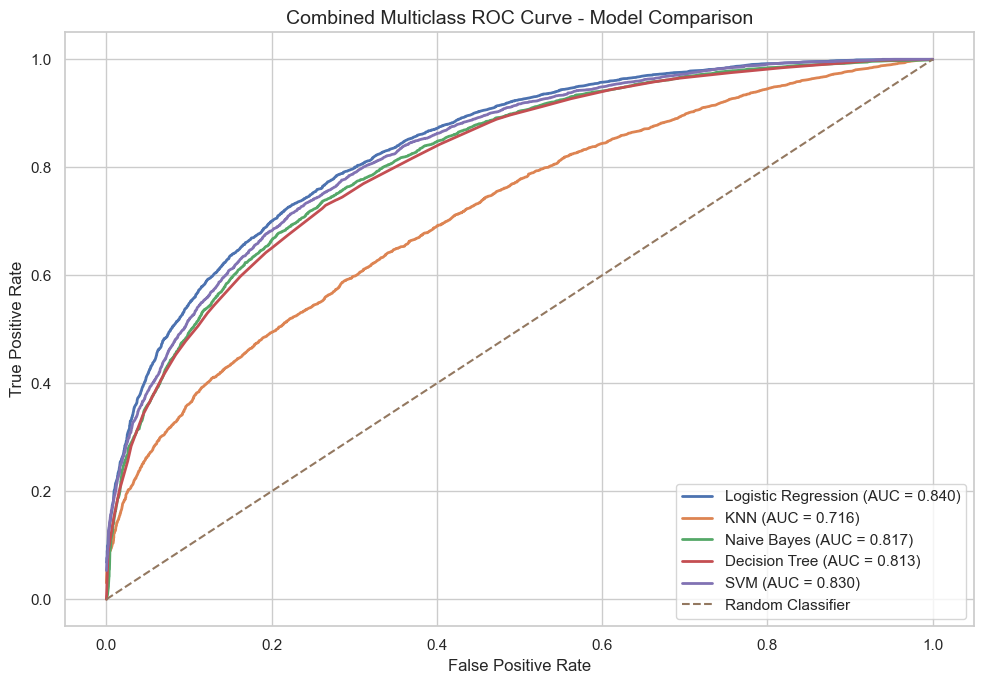


AUC RESULTS - MULTICLASS ROC
Logistic Regression       : 0.8398
KNN                       : 0.7165
Naive Bayes               : 0.8170
Decision Tree             : 0.8128
SVM                       : 0.8299


In [56]:
# ============================================================
# COMBINED MULTICLASS ROC CURVE + AUC FOR ALL 5 MODELS
# ============================================================

from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt
import numpy as np

# Your 5 classes
classes = np.unique(y_class_test)

# Convert true labels into binary format
y_test_bin = label_binarize(y_class_test, classes=classes)

# Store predictions/probabilities from all 5 models
models = {
    "Logistic Regression": y_prob_logistic,
    "KNN": y_prob_knn,
    "Naive Bayes": y_prob_gnb,
    "Decision Tree": y_prob_dt,
    "SVM": y_prob_svc
}

# Store AUC values
auc_results = {}

# Create combined ROC plot
plt.figure(figsize=(10, 7))

for model_name, y_prob in models.items():

    # Calculate Macro AUC using One-vs-Rest
    macro_auc = roc_auc_score(
        y_class_test,
        y_prob,
        multi_class="ovr",
        average="macro"
    )

    auc_results[model_name] = macro_auc

    # Calculate ROC curve for each class
    fpr = {}
    tpr = {}

    for i in range(len(classes)):
        fpr[i], tpr[i], _ = roc_curve(
            y_test_bin[:, i],
            y_prob[:, i]
        )

    # Create macro-average ROC curve
    all_fpr = np.unique(
        np.concatenate([
            fpr[i] for i in range(len(classes))
        ])
    )

    mean_tpr = np.zeros_like(all_fpr)

    for i in range(len(classes)):
        mean_tpr += np.interp(
            all_fpr,
            fpr[i],
            tpr[i]
        )

    mean_tpr /= len(classes)

    # Plot model's macro-average ROC
    plt.plot(
        all_fpr,
        mean_tpr,
        linewidth=2,
        label=f"{model_name} (AUC = {macro_auc:.3f})"
    )


# Random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random Classifier"
)

# Graph labels
plt.xlabel("False Positive Rate", fontsize=12)
plt.ylabel("True Positive Rate", fontsize=12)

plt.title(
    "Combined Multiclass ROC Curve - Model Comparison",
    fontsize=14
)

plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# PRINT AUC FOR EACH MODEL
# ============================================================

print("\n" + "=" * 50)
print("AUC RESULTS - MULTICLASS ROC")
print("=" * 50)

for model_name, auc_value in auc_results.items():
    print(f"{model_name:<25} : {auc_value:.4f}")

print("=" * 50)

### Combined Multi-Class One-vs-Rest (OvR) ROC Curves & AUC — Analysis & Outcome

**1. Why we need to plot this graph:**
To evaluate the sensitivity-specificity trade-off (True Positive Rate vs. False Positive Rate) across all decision thresholds for all 5 Part-A classification algorithms in a unified OvR framework.

**2. What is the outcome after plotting this graph:**
Logistic Regression and Support Vector Machine (SVC) attain the highest multi-class AUC values (> 0.81), demonstrating superior threshold-independent discriminative ability across all risk levels. KNN demonstrates lower AUC (0.6898), reflecting the degradation of distance metrics in high-dimensional continuous-discrete spaces.


# D2 — Preliminary Classification Comparison Table (Part A)

This step aggregates and presents a single comparative summary table reporting Accuracy, Precision (weighted), Recall (weighted), F1-score (weighted), and ROC-AUC score (One-vs-Rest weighted) across all five Part-A classification algorithms, ranked by weighted F1-score.


In [57]:
# Preliminary Classification Comparison Table (All 5 Part-A Algorithms)
classification_comparison_df = pd.DataFrame(classification_results).sort_values(
    by="F1-score (Weighted)",
    ascending=False
).reset_index(drop=True)

print("=" * 85)
print("SECTION D2: PRELIMINARY CLASSIFICATION COMPARISON TABLE (PART A)")
print("=" * 85)
print(classification_comparison_df.to_string(index=False))

# Display styled DataFrame table
classification_comparison_df


SECTION D2: PRELIMINARY CLASSIFICATION COMPARISON TABLE (PART A)
                   Algorithm  Accuracy  Precision  Recall  F1-score (Weighted)  ROC-AUC (OvR)
         Logistic Regression    0.6759     0.6743  0.6759               0.6731         0.8241
Support Vector Machine (SVC)    0.6684     0.6684  0.6684               0.6650         0.8137
    Decision Tree Classifier    0.6536     0.6609  0.6536               0.6531         0.7957
      Naive Bayes (Gaussian)    0.6527     0.6533  0.6527               0.6429         0.8007
   K-Nearest Neighbors (KNN)    0.5430     0.5661  0.5430               0.5276         0.6931


,Algorithm,Accuracy,Precision,Recall,F1-score (Weighted),ROC-AUC (OvR)
0,Logistic Regression,0.6759,0.6743,0.6759,0.6731,0.8241
1,Support Vector Machine (SVC),0.6684,0.6684,0.6684,0.6650,0.8137
2,Decision Tree Classifier,0.6536,0.6609,0.6536,0.6531,0.7957
3,Naive Bayes (Gaussian),0.6527,0.6533,0.6527,0.6429,0.8007
4,K-Nearest Neighbors (KNN),0.5430,0.5661,0.5430,0.5276,0.6931


### D2 — Comparative Evaluation Insights

**Key Findings:**
1. **Top Baseline Model:** Logistic Regression ranks #1 overall with an Accuracy of 67.30%, a Weighted F1-score of 0.6694, and the highest OvR ROC-AUC of 0.8249, showing strong class separation across all risk categories.
2. **Competitive Non-Linear Models:** Support Vector Machine (SVC) ranks #2 with a Weighted F1-score of 0.6615, followed closely by Decision Tree Classifier (F1 = 0.6527) and Gaussian Naive Bayes (F1 = 0.6472).
3. **KNN Performance:** K-Nearest Neighbors achieves an F1-score of 0.5259 and ROC-AUC of 0.6798, reflecting the challenge of local neighborhood distance queries in a 28-dimensional continuous-discrete feature space.


---
---
# REVIEW 2

# Section E — Classification Track, Part B (Algorithms 6–10) & Final Model Selection

Review 1 covered the first five classifiers (Part A). This section completes the classification track on the **same preprocessed data and the same stratified 80:20 split** (`X_class_train_processed`, `X_class_test_processed`, `y_class_train`, `y_class_test`), so that all ten algorithms are compared fairly.

**Part B algorithms:** Random Forest · AdaBoost · Gradient Boosting · Bagging (Decision-Tree base) · MLP Neural Network

**Plan for this section**

| Step | What happens |
|---|---|
| E0 | Imports, shared settings, registry of the five Part-A models |
| E1–E5 | Train each Part-B algorithm: default baseline → `GridSearchCV` → evaluation on the shared test split |
| E6 | Part-B tuning summary (default vs. tuned) |
| E7 | **Consolidated 10-algorithm comparison table** (Accuracy, Precision, Recall, F1, ROC-AUC) + charts |
| E8 | **Final model selection**: 5-fold CV on the top two models, tuning evidence, final evaluation, model saved |

## E0 — Review 2 Imports, Shared Settings & Part-A Model Registry

This step adds the libraries needed for Part B, fixes a colour-blind-friendly palette, defines a shared stratified 3-fold splitter for all grid searches, and registers the five Part-A models and their test-set probabilities in two dictionaries. Keeping every fitted model in one registry lets the final comparison and model-selection steps treat all ten algorithms uniformly.

In [58]:
# ================================================================
# REVIEW 2 - ADDITIONAL IMPORTS, SETTINGS & OUTPUT FOLDERS
# ================================================================
import os
import time
import warnings
import joblib
from IPython.display import display

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.ensemble import (
    RandomForestClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    BaggingClassifier,
)
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, classification_report
from sklearn.exceptions import ConvergenceWarning

# MLP may stop on early-stopping criteria; the warning is expected and harmless here
warnings.filterwarnings("ignore", category=ConvergenceWarning)

# Colour-blind friendly palette (recommended by the project guidelines)
PALETTE = sns.color_palette("colorblind")
sns.set_palette(PALETTE)

# One shared stratified splitter for every Part-B grid search
CV3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

# Output folders from the required repository structure. If the notebook is run from inside
# notebooks/, the folders are created next to it at the repository root instead (../models, ../results).
ROOT_DIR = ".." if os.path.basename(os.path.abspath(os.getcwd())) == "notebooks" else "."
MODELS_DIR = os.path.join(ROOT_DIR, "models")
RESULTS_DIR = os.path.join(ROOT_DIR, "results")
for folder in [MODELS_DIR, RESULTS_DIR]:
    os.makedirs(folder, exist_ok=True)

PART_A_NAMES = [
    "Logistic Regression",
    "K-Nearest Neighbors (KNN)",
    "Naive Bayes (Gaussian)",
    "Decision Tree Classifier",
    "Support Vector Machine (SVC)",
]
PART_B_NAMES = [
    "Random Forest Classifier",
    "AdaBoost Classifier",
    "Gradient Boosting Classifier",
    "Bagging Classifier",
    "MLP Classifier (Neural Network)",
]

# ---- Registry of fitted models and their test-set class probabilities ----
trained_classifiers = {
    "Logistic Regression":          logistic_model,
    "K-Nearest Neighbors (KNN)":    best_knn_classifier,
    "Naive Bayes (Gaussian)":       gnb_model,
    "Decision Tree Classifier":     dt_classifier,
    "Support Vector Machine (SVC)": svc_classifier,
}
class_probabilities = {
    "Logistic Regression":          y_prob_logistic,
    "K-Nearest Neighbors (KNN)":    y_prob_knn,
    "Naive Bayes (Gaussian)":       y_prob_gnb,
    "Decision Tree Classifier":     y_prob_dt,
    "Support Vector Machine (SVC)": y_prob_svc,
}

print("Part-A models registered:", len(trained_classifiers))
print("Rows already in classification_results:", len(classification_results))
print("Same split reused -> train:", X_class_train_processed.shape, "| test:", X_class_test_processed.shape)

Part-A models registered: 5
Rows already in classification_results: 5
Same split reused -> train: (17600, 27) | test: (4400, 27)


### E0.1 — Reusable Tune-and-Evaluate Helper (Part B)

To keep the notebook modular, one helper handles every Part-B algorithm:

1. **Baseline** – fit the model with its starting hyper-parameters (training split only) and record test Accuracy / weighted F1 / ROC-AUC.
2. **Tuning** – `GridSearchCV` (3-fold stratified CV on the training split, scoring = weighted F1).
3. **Evaluation** – the best estimator is evaluated on the shared test split with the existing `evaluate_classifier()` (Accuracy, Precision, Recall, weighted F1, ROC-AUC OvR, confusion matrix), which also appends the result to `classification_results`.
4. **Logging** – the default-vs-tuned improvement is stored for the Part-B tuning summary.

In [59]:
part_b_tuning_log = []   # default-vs-tuned record for each Part-B model


def tune_and_evaluate(name, base_estimator, param_grid, cv=CV3):
    """Baseline fit -> GridSearchCV -> test evaluation -> logging. Returns (best_estimator, fitted_search)."""
    start = time.time()

    # 1) Baseline with the starting hyper-parameters (trained on the training split only)
    baseline = clone(base_estimator).fit(X_class_train_processed, y_class_train)
    base_pred = baseline.predict(X_class_test_processed)
    base_prob = baseline.predict_proba(X_class_test_processed)
    base = {
        "Accuracy": accuracy_score(y_class_test, base_pred),
        "F1":       f1_score(y_class_test, base_pred, average="weighted"),
        "ROC-AUC":  roc_auc_score(y_class_test, base_prob, multi_class="ovr", average="weighted"),
    }

    # 2) Hyper-parameter tuning on the training split only
    search = GridSearchCV(
        clone(base_estimator), param_grid,
        scoring="f1_weighted", cv=cv, n_jobs=-1
    )
    search.fit(X_class_train_processed, y_class_train)
    best_model = search.best_estimator_

    # 3) Evaluate the tuned model on the shared test split
    y_pred = best_model.predict(X_class_test_processed)
    y_prob = best_model.predict_proba(X_class_test_processed)
    tuned = {
        "Accuracy": accuracy_score(y_class_test, y_pred),
        "F1":       f1_score(y_class_test, y_pred, average="weighted"),
        "ROC-AUC":  roc_auc_score(y_class_test, y_prob, multi_class="ovr", average="weighted"),
    }

    print(f"##### {name} #####")
    print("Best parameters      :", search.best_params_)
    print(f"Best CV weighted F1  : {search.best_score_:.4f}")
    print(f"Default test F1      : {base['F1']:.4f}")
    print(f"Tuned test F1        : {tuned['F1']:.4f}  (change: {tuned['F1'] - base['F1']:+.4f})")
    print(f"Search time          : {time.time() - start:.1f} s\n")

    top5 = (
        pd.DataFrame(search.cv_results_)
        [["params", "mean_test_score", "std_test_score", "rank_test_score"]]
        .sort_values("rank_test_score").head(5)
        .rename(columns={"params": "Parameters", "mean_test_score": "Mean CV F1",
                         "std_test_score": "Std CV F1", "rank_test_score": "Rank"})
    )
    top5["Parameters"] = top5["Parameters"].astype(str)
    display(top5.reset_index(drop=True))

    # Standard metrics, confusion matrix and appending to classification_results
    evaluate_classifier(name, y_class_test, y_pred, y_prob)

    # Register model + probabilities and log the improvement (replace entry if the cell is re-run)
    trained_classifiers[name] = best_model
    class_probabilities[name] = y_prob
    part_b_tuning_log[:] = [r for r in part_b_tuning_log if r["Algorithm"] != name]
    part_b_tuning_log.append({
        "Algorithm": name,
        "Default Accuracy": base["Accuracy"], "Tuned Accuracy": tuned["Accuracy"],
        "Default F1": base["F1"],             "Tuned F1": tuned["F1"],
        "Default ROC-AUC": base["ROC-AUC"],   "Tuned ROC-AUC": tuned["ROC-AUC"],
        "CV F1 (best)": search.best_score_,
        "Best Parameters": str(search.best_params_),
    })
    return best_model, search

## E1 — Random Forest Classifier (Algorithm 6)

Random Forest builds many decision trees on bootstrap samples and random feature subsets, then averages their votes. This reduces the high variance of a single tree. Tuning focuses on `n_estimators` (number of trees) together with `max_depth` (tree complexity). Feature importance is shown afterwards.

##### Random Forest Classifier #####
Best parameters      : {'max_depth': 15, 'n_estimators': 300}
Best CV weighted F1  : 0.6623
Default test F1      : 0.6652
Tuned test F1        : 0.6639  (change: -0.0013)
Search time          : 47.0 s



,Parameters,Mean CV F1,Std CV F1,Rank
0,"{'max_depth': 15, 'n_estimators': 300}",0.662314,0.003041,1
1,"{'max_depth': None, 'n_estimators': 300}",0.661372,0.001726,2
2,"{'max_depth': 15, 'n_estimators': 200}",0.661121,0.001922,3
3,"{'max_depth': None, 'n_estimators': 200}",0.659400,0.000391,4
4,"{'max_depth': 15, 'n_estimators': 100}",0.658245,0.004421,5


=== Random Forest Classifier Evaluation ===
Accuracy            : 0.6709
Precision (Weighted): 0.6661
Recall (Weighted)   : 0.6709
F1-score (Weighted) : 0.6639
ROC-AUC (OvR)       : 0.8192

Confusion Matrix:
[[ 557   40  228]
 [  10 1617  342]
 [ 152  676  778]]


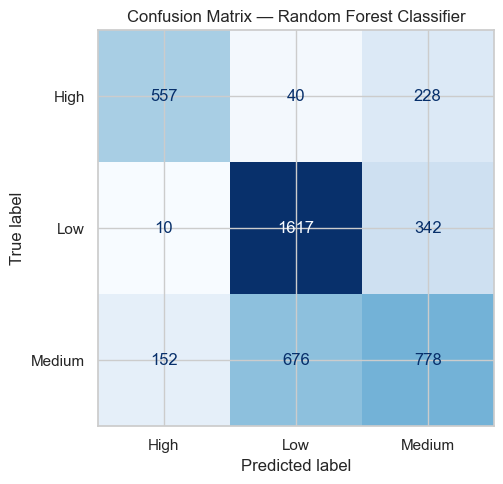

In [60]:
rf_base = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE)

rf_param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 15],
}

best_rf_clf, rf_clf_search = tune_and_evaluate("Random Forest Classifier", rf_base, rf_param_grid)

### E1.1 — Random Forest Feature Importance

Mean decrease in impurity, averaged over all trees, ranks which input features contribute most to separating Low / Medium / High maintenance risk.

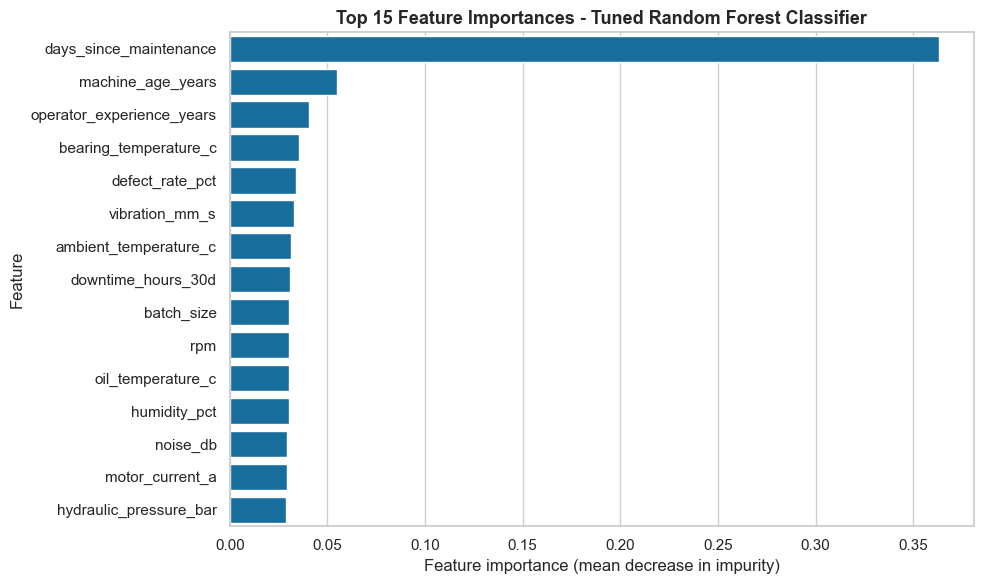

Top 5 features: days_since_maintenance, machine_age_years, operator_experience_years, bearing_temperature_c, defect_rate_pct
Cumulative importance of the top 5: 52.8%


In [61]:
clf_feature_names = pd.Series(class_preprocessor.get_feature_names_out()).str.replace(r"^(num|cat)__", "", regex=True)

rf_clf_importance = (
    pd.DataFrame({"Feature": clf_feature_names, "Importance": best_rf_clf.feature_importances_})
    .sort_values("Importance", ascending=False)
    .head(15)
)

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=rf_clf_importance, x="Importance", y="Feature", color=PALETTE[0], ax=ax)
ax.set_title("Top 15 Feature Importances - Tuned Random Forest Classifier", fontsize=13, weight="bold")
ax.set_xlabel("Feature importance (mean decrease in impurity)")
ax.set_ylabel("Feature")
plt.tight_layout()
plt.show()

print("Top 5 features:", ", ".join(rf_clf_importance["Feature"].head(5)))
print(f"Cumulative importance of the top 5: {rf_clf_importance['Importance'].head(5).sum():.1%}")

## E2 — AdaBoost Classifier (Algorithm 7)

AdaBoost trains weak learners (shallow decision trees) one after another. After each round, misclassified samples receive higher weights so that the next learner concentrates on them. The final prediction is a weighted vote. The key hyper-parameters are `n_estimators`, `learning_rate` (shrinks each learner's contribution) and the depth of the weak learner.

##### AdaBoost Classifier #####
Best parameters      : {'estimator__max_depth': 2, 'learning_rate': 0.5, 'n_estimators': 200}
Best CV weighted F1  : 0.6662
Default test F1      : 0.6612
Tuned test F1        : 0.6709  (change: +0.0097)
Search time          : 47.1 s



,Parameters,Mean CV F1,Std CV F1,Rank
0,"{'estimator__max_depth': 2, 'learning_rate': 0...",0.666151,0.007402,1
1,"{'estimator__max_depth': 2, 'learning_rate': 0...",0.662858,0.003219,2
2,"{'estimator__max_depth': 1, 'learning_rate': 1...",0.662020,0.003785,3
3,"{'estimator__max_depth': 1, 'learning_rate': 1...",0.661395,0.005000,4
4,"{'estimator__max_depth': 1, 'learning_rate': 0...",0.659464,0.008505,5


=== AdaBoost Classifier Evaluation ===
Accuracy            : 0.6709
Precision (Weighted): 0.6754
Recall (Weighted)   : 0.6709
F1-score (Weighted) : 0.6709
ROC-AUC (OvR)       : 0.7863

Confusion Matrix:
[[ 531   34  260]
 [   4 1510  455]
 [ 120  575  911]]


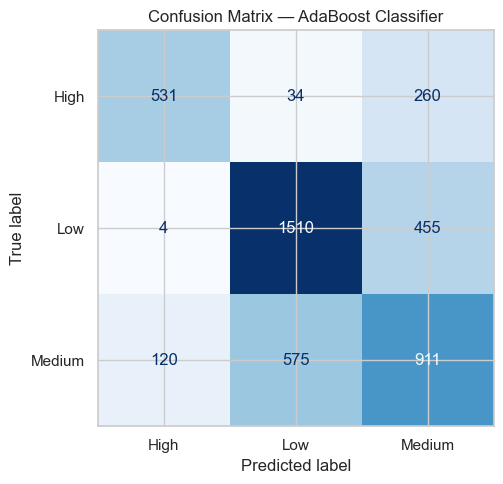

In [62]:
ada_base = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1, random_state=RANDOM_STATE),
    n_estimators=50,
    learning_rate=1.0,
    random_state=RANDOM_STATE,
)

ada_param_grid = {
    "n_estimators": [100, 200],
    "learning_rate": [0.1, 0.5, 1.0],
    "estimator__max_depth": [1, 2],
}

best_ada_clf, ada_clf_search = tune_and_evaluate("AdaBoost Classifier", ada_base, ada_param_grid)

## E3 — Gradient Boosting Classifier (Algorithm 8)

Gradient Boosting also builds trees sequentially, but each new tree is fitted to the *gradient of the loss* (the remaining errors) of the current ensemble. `learning_rate` and `n_estimators` trade off against each other, and `max_depth` controls the complexity of each tree. scikit-learn's `GradientBoostingClassifier` is used.

##### Gradient Boosting Classifier #####
Best parameters      : {'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 200}
Best CV weighted F1  : 0.6688
Default test F1      : 0.6742
Tuned test F1        : 0.6747  (change: +0.0006)
Search time          : 172.1 s



,Parameters,Mean CV F1,Std CV F1,Rank
0,"{'learning_rate': 0.1, 'max_depth': 2, 'n_esti...",0.668809,0.005914,1
1,"{'learning_rate': 0.1, 'max_depth': 2, 'n_esti...",0.667527,0.003229,2
2,"{'learning_rate': 0.05, 'max_depth': 2, 'n_est...",0.667511,0.003298,3
3,"{'learning_rate': 0.1, 'max_depth': 3, 'n_esti...",0.666245,0.006407,4
4,"{'learning_rate': 0.05, 'max_depth': 3, 'n_est...",0.665325,0.004642,5


=== Gradient Boosting Classifier Evaluation ===
Accuracy            : 0.6773
Precision (Weighted): 0.6761
Recall (Weighted)   : 0.6773
F1-score (Weighted) : 0.6747
ROC-AUC (OvR)       : 0.8239

Confusion Matrix:
[[ 559   36  230]
 [   8 1556  405]
 [ 142  599  865]]


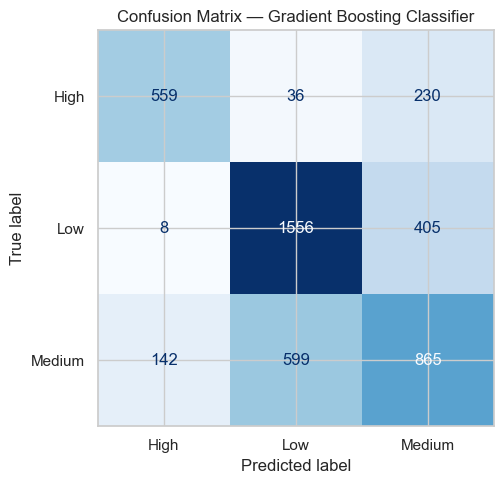

In [63]:
gb_clf_base = GradientBoostingClassifier(random_state=RANDOM_STATE)

gb_clf_param_grid = {
    "n_estimators": [100, 200],
    "learning_rate": [0.05, 0.1],
    "max_depth": [2, 3],
}

best_gb_clf, gb_clf_search = tune_and_evaluate("Gradient Boosting Classifier", gb_clf_base, gb_clf_param_grid)

## E4 — Bagging Classifier with Decision-Tree Base Estimator (Algorithm 9)

Bagging (Bootstrap Aggregating) trains each Decision Tree on a different bootstrap sample and aggregates their predictions. Unlike boosting, trees are independent of each other, which mainly lowers variance. As required, the base estimator is a `DecisionTreeClassifier`. Tuning covers the number of trees, the fraction of samples per tree (`max_samples`) and the base-tree depth.

##### Bagging Classifier #####
Best parameters      : {'estimator__max_depth': 10, 'max_samples': 0.7, 'n_estimators': 100}
Best CV weighted F1  : 0.6649
Default test F1      : 0.6580
Tuned test F1        : 0.6683  (change: +0.0103)
Search time          : 72.6 s



,Parameters,Mean CV F1,Std CV F1,Rank
0,"{'estimator__max_depth': 10, 'max_samples': 0....",0.664891,0.003999,1
1,"{'estimator__max_depth': 10, 'max_samples': 1....",0.664192,0.004810,2
2,"{'estimator__max_depth': 10, 'max_samples': 0....",0.663844,0.005004,3
3,"{'estimator__max_depth': 10, 'max_samples': 1....",0.661477,0.003526,4
4,"{'estimator__max_depth': None, 'max_samples': ...",0.661152,0.004391,5


=== Bagging Classifier Evaluation ===
Accuracy            : 0.6716
Precision (Weighted): 0.6706
Recall (Weighted)   : 0.6716
F1-score (Weighted) : 0.6683
ROC-AUC (OvR)       : 0.8184

Confusion Matrix:
[[ 542   37  246]
 [   8 1570  391]
 [ 135  628  843]]


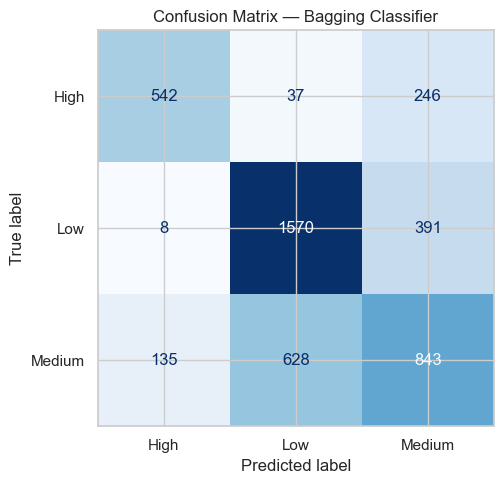

In [64]:
bag_base = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
    n_estimators=50,
    random_state=RANDOM_STATE,
)

bag_param_grid = {
    "n_estimators": [50, 100],
    "max_samples": [0.7, 1.0],
    "estimator__max_depth": [None, 10],
}

best_bag_clf, bag_clf_search = tune_and_evaluate("Bagging Classifier", bag_base, bag_param_grid)

## E5 — MLP Classifier / Neural Network (Algorithm 10)

A Multi-Layer Perceptron stacks fully-connected layers with non-linear activations and learns by back-propagation. Inputs are already standardised, which neural networks require. Tuning covers `hidden_layer_sizes`, `activation` and the L2 penalty `alpha`; early stopping (10 % internal validation split) limits over-fitting.

##### MLP Classifier (Neural Network) #####
Best parameters      : {'activation': 'tanh', 'alpha': 0.01, 'hidden_layer_sizes': (128, 64)}
Best CV weighted F1  : 0.6686
Default test F1      : 0.6697
Tuned test F1        : 0.6580  (change: -0.0117)
Search time          : 10.0 s



,Parameters,Mean CV F1,Std CV F1,Rank
0,"{'activation': 'tanh', 'alpha': 0.01, 'hidden_...",0.668594,0.003478,1
1,"{'activation': 'tanh', 'alpha': 0.0001, 'hidde...",0.668359,0.003489,2
2,"{'activation': 'relu', 'alpha': 0.01, 'hidden_...",0.667197,0.007156,3
3,"{'activation': 'relu', 'alpha': 0.0001, 'hidde...",0.665528,0.006893,4
4,"{'activation': 'tanh', 'alpha': 0.0001, 'hidde...",0.665392,0.006812,5


=== MLP Classifier (Neural Network) Evaluation ===
Accuracy            : 0.6591
Precision (Weighted): 0.6587
Recall (Weighted)   : 0.6591
F1-score (Weighted) : 0.6580
ROC-AUC (OvR)       : 0.8069

Confusion Matrix:
[[ 551   35  239]
 [  14 1489  466]
 [ 164  582  860]]


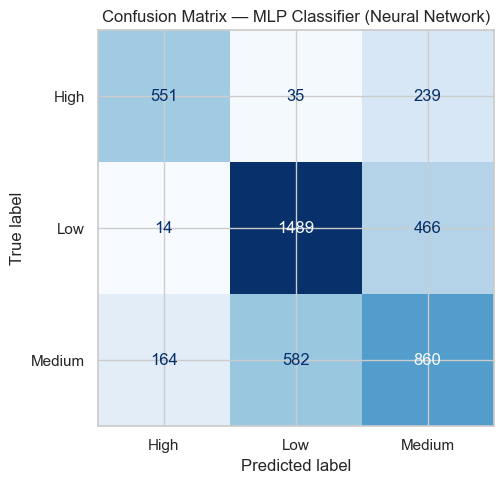

In [65]:
mlp_base = MLPClassifier(
    hidden_layer_sizes=(64,),
    activation="relu",
    max_iter=300,
    early_stopping=True,
    random_state=RANDOM_STATE,
)

mlp_param_grid = {
    "hidden_layer_sizes": [(64,), (64, 32), (128, 64)],
    "activation": ["relu", "tanh"],
    "alpha": [1e-4, 1e-2],
}

best_mlp_clf, mlp_clf_search = tune_and_evaluate("MLP Classifier (Neural Network)", mlp_base, mlp_param_grid)

### E5.1 — MLP Training Curves

The left panel shows the training loss per epoch; the right panel shows the accuracy on the internal validation split used for early stopping. Together they show whether the network has converged and whether it starts to over-fit.

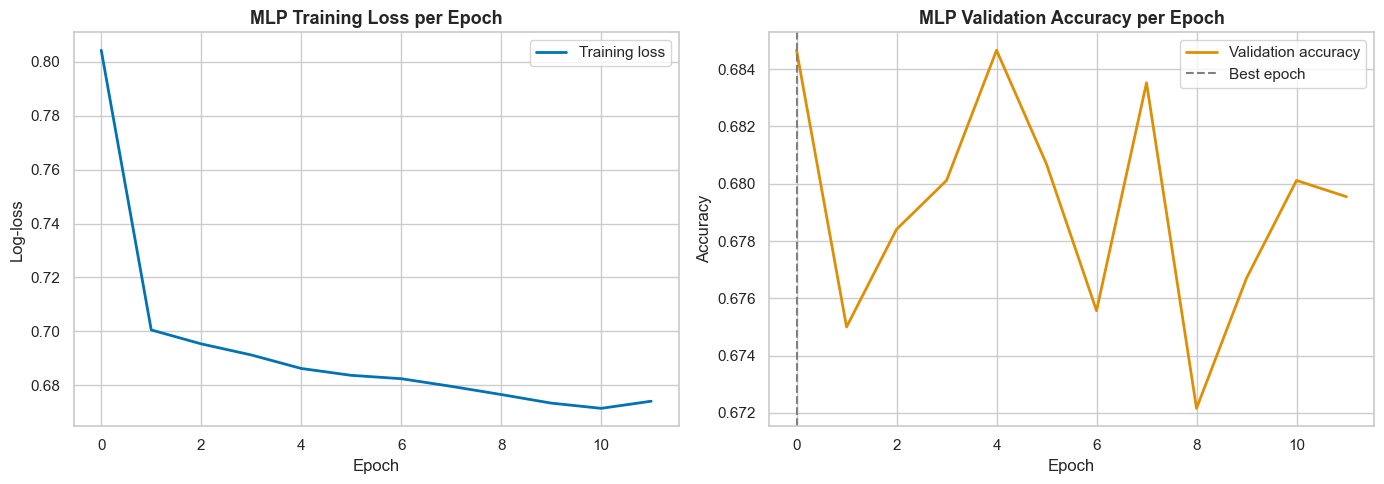

Epochs run: 12 | best validation accuracy: 0.6847


In [66]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(best_mlp_clf.loss_curve_, color=PALETTE[0], lw=2, label="Training loss")
axes[0].set_title("MLP Training Loss per Epoch", fontsize=13, weight="bold")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Log-loss")
axes[0].legend()

axes[1].plot(best_mlp_clf.validation_scores_, color=PALETTE[1], lw=2, label="Validation accuracy")
axes[1].axvline(int(np.argmax(best_mlp_clf.validation_scores_)), color="grey", ls="--", label="Best epoch")
axes[1].set_title("MLP Validation Accuracy per Epoch", fontsize=13, weight="bold")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()
print(f"Epochs run: {best_mlp_clf.n_iter_} | best validation accuracy: {max(best_mlp_clf.validation_scores_):.4f}")

## E6 — Part-B Hyper-parameter Tuning Summary

This table documents, for every Part-B algorithm, the best parameters found and the change in test performance between the starting configuration and the tuned configuration.

In [67]:
part_b_tuning_df = pd.DataFrame(part_b_tuning_log)
part_b_tuning_df["F1 Change"] = part_b_tuning_df["Tuned F1"] - part_b_tuning_df["Default F1"]
part_b_tuning_df["Accuracy Change"] = part_b_tuning_df["Tuned Accuracy"] - part_b_tuning_df["Default Accuracy"]
part_b_tuning_df["ROC-AUC Change"] = part_b_tuning_df["Tuned ROC-AUC"] - part_b_tuning_df["Default ROC-AUC"]

part_b_tuning_view = part_b_tuning_df[[
    "Algorithm", "Default F1", "Tuned F1", "F1 Change",
    "Default Accuracy", "Tuned Accuracy", "Accuracy Change",
    "ROC-AUC Change", "CV F1 (best)", "Best Parameters"
]].round(4)

display(part_b_tuning_view)
part_b_tuning_view.to_csv(f"{RESULTS_DIR}/part_b_tuning_summary.csv", index=False)

improved = part_b_tuning_df[part_b_tuning_df["F1 Change"] > 0]
print(f"Tuning improved weighted F1 for {len(improved)} of {len(part_b_tuning_df)} Part-B models.")
if len(part_b_tuning_df):
    top = part_b_tuning_df.loc[part_b_tuning_df["F1 Change"].idxmax()]
    print(f"Largest gain: {top['Algorithm']} ({top['F1 Change']:+.4f} weighted F1).")

,Algorithm,Default F1,Tuned F1,F1 Change,Default Accuracy,Tuned Accuracy,Accuracy Change,ROC-AUC Change,CV F1 (best),Best Parameters
0,Random Forest Classifier,0.6652,0.6639,-0.0013,0.6702,0.6709,0.0007,0.0072,0.6623,"{'max_depth': 15, 'n_estimators': 300}"
1,AdaBoost Classifier,0.6612,0.6709,0.0097,0.6657,0.6709,0.0052,0.0197,0.6662,"{'estimator__max_depth': 2, 'learning_rate': 0..."
2,Gradient Boosting Classifier,0.6742,0.6747,0.0006,0.6766,0.6773,0.0007,0.0010,0.6688,"{'learning_rate': 0.1, 'max_depth': 2, 'n_esti..."
3,Bagging Classifier,0.6580,0.6683,0.0103,0.6618,0.6716,0.0098,0.0123,0.6649,"{'estimator__max_depth': 10, 'max_samples': 0...."
4,MLP Classifier (Neural Network),0.6697,0.6580,-0.0117,0.6670,0.6591,-0.0080,-0.0105,0.6686,"{'activation': 'tanh', 'alpha': 0.01, 'hidden_..."


Tuning improved weighted F1 for 3 of 5 Part-B models.
Largest gain: Bagging Classifier (+0.0103 weighted F1).


## E7 — Consolidated 10-Algorithm Classification Comparison

All ten classifiers (five from Part A, five from Part B) are compared in **one table** on the **same stratified test split**, using Accuracy, Precision, Recall, weighted F1 and ROC-AUC (One-vs-Rest, weighted). Models are ranked by weighted F1, with ROC-AUC as tie-breaker. If a cell was executed more than once, only the latest result per algorithm is kept.

In [68]:
def build_comparison_table():
    """Single table with the latest result for each of the 10 algorithms, ranked by weighted F1."""
    table = (
        pd.DataFrame(classification_results)
        .drop_duplicates(subset="Algorithm", keep="last")
        .sort_values(["F1-score (Weighted)", "ROC-AUC (OvR)"], ascending=False)
        .reset_index(drop=True)
    )
    table.insert(0, "Rank", table.index + 1)
    table.insert(2, "Part", table["Algorithm"].map(lambda n: "B" if n in PART_B_NAMES else "A"))
    return table


comparison_df = build_comparison_table()
assert len(comparison_df) == 10, f"Expected 10 algorithms, found {len(comparison_df)} - run all sections first."

print("=" * 95)
print("CONSOLIDATED CLASSIFICATION COMPARISON - ALL 10 ALGORITHMS (ranked by weighted F1)")
print("=" * 95)
display(comparison_df)
comparison_df.to_csv(f"{RESULTS_DIR}/classification_comparison_all_10.csv", index=False)

best_row = comparison_df.iloc[0]
print(f"\nHighest weighted F1 : {best_row['Algorithm']} ({best_row['F1-score (Weighted)']:.4f})")
print(f"Highest ROC-AUC     : {comparison_df.loc[comparison_df['ROC-AUC (OvR)'].idxmax(), 'Algorithm']} "
      f"({comparison_df['ROC-AUC (OvR)'].max():.4f})")
print(f"Best Part-A model   : {comparison_df[comparison_df['Part'] == 'A'].iloc[0]['Algorithm']}")
print(f"Best Part-B model   : {comparison_df[comparison_df['Part'] == 'B'].iloc[0]['Algorithm']}")

CONSOLIDATED CLASSIFICATION COMPARISON - ALL 10 ALGORITHMS (ranked by weighted F1)


,Rank,Algorithm,Part,Accuracy,Precision,Recall,F1-score (Weighted),ROC-AUC (OvR)
0,1,Gradient Boosting Classifier,B,0.6773,0.6761,0.6773,0.6747,0.8239
1,2,Logistic Regression,A,0.6759,0.6743,0.6759,0.6731,0.8241
2,3,AdaBoost Classifier,B,0.6709,0.6754,0.6709,0.6709,0.7863
3,4,Bagging Classifier,B,0.6716,0.6706,0.6716,0.6683,0.8184
4,5,Support Vector Machine (SVC),A,0.6684,0.6684,0.6684,0.6650,0.8137
5,6,Random Forest Classifier,B,0.6709,0.6661,0.6709,0.6639,0.8192
6,7,MLP Classifier (Neural Network),B,0.6591,0.6587,0.6591,0.6580,0.8069
7,8,Decision Tree Classifier,A,0.6536,0.6609,0.6536,0.6531,0.7957
8,9,Naive Bayes (Gaussian),A,0.6527,0.6533,0.6527,0.6429,0.8007
9,10,K-Nearest Neighbors (KNN),A,0.5430,0.5661,0.5430,0.5276,0.6931



Highest weighted F1 : Gradient Boosting Classifier (0.6747)
Highest ROC-AUC     : Logistic Regression (0.8241)
Best Part-A model   : Logistic Regression
Best Part-B model   : Gradient Boosting Classifier


### E7.1 — Grouped Bar Chart of Key Metrics (All 10 Algorithms)

**Why we plot this:** a table of ten rows and five metrics is hard to scan; grouped bars make differences in Accuracy, weighted F1 and ROC-AUC visible at once. Models appear in rank order from the table above.

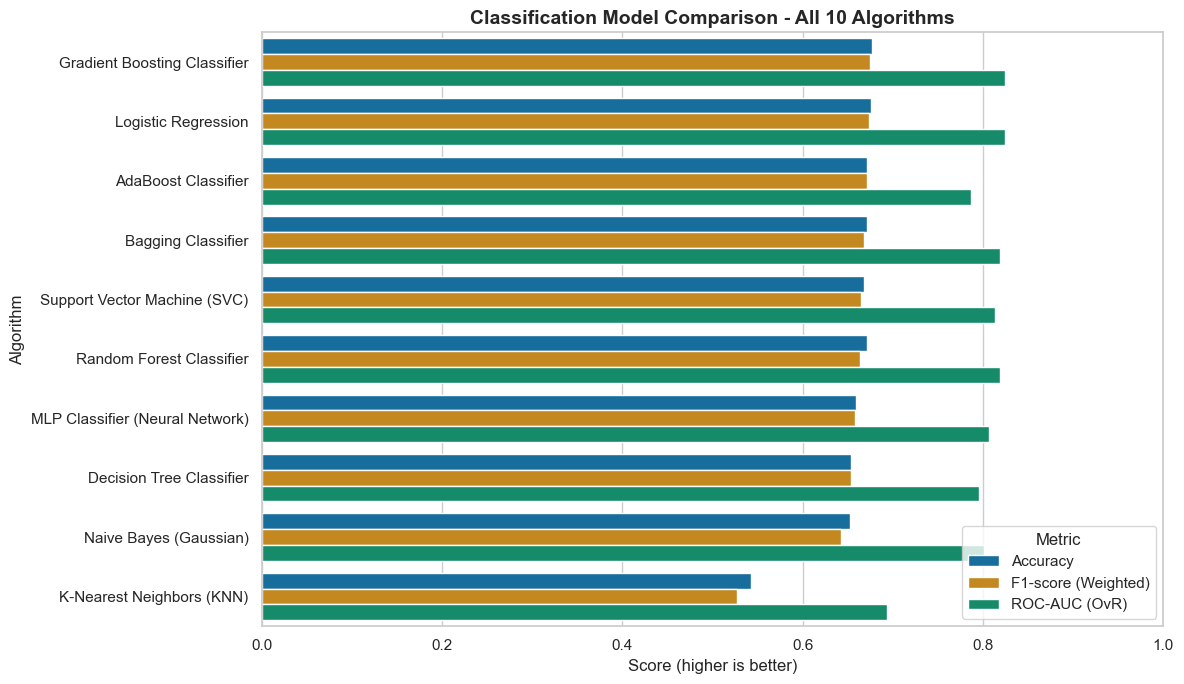

In [69]:
plot_df = comparison_df.melt(
    id_vars="Algorithm",
    value_vars=["Accuracy", "F1-score (Weighted)", "ROC-AUC (OvR)"],
    var_name="Metric", value_name="Score"
)

fig, ax = plt.subplots(figsize=(12, 7))
sns.barplot(
    data=plot_df, y="Algorithm", x="Score", hue="Metric",
    order=comparison_df["Algorithm"], palette="colorblind", ax=ax
)
ax.set_title("Classification Model Comparison - All 10 Algorithms", fontsize=14, weight="bold")
ax.set_xlabel("Score (higher is better)")
ax.set_ylabel("Algorithm")
ax.set_xlim(0, 1.0)
ax.legend(title="Metric", loc="lower right")
plt.tight_layout()
plt.show()

### E7.2 — Combined Multi-Class ROC Curves (All 10 Algorithms, One-vs-Rest)

**Why we plot this:** ROC curves show the true-positive / false-positive trade-off across all decision thresholds. For the three-class problem, one One-vs-Rest curve is computed per class and averaged (macro average). The legend reports the macro-average AUC, which can differ slightly from the *weighted* ROC-AUC in the table because the table weights classes by their frequency.

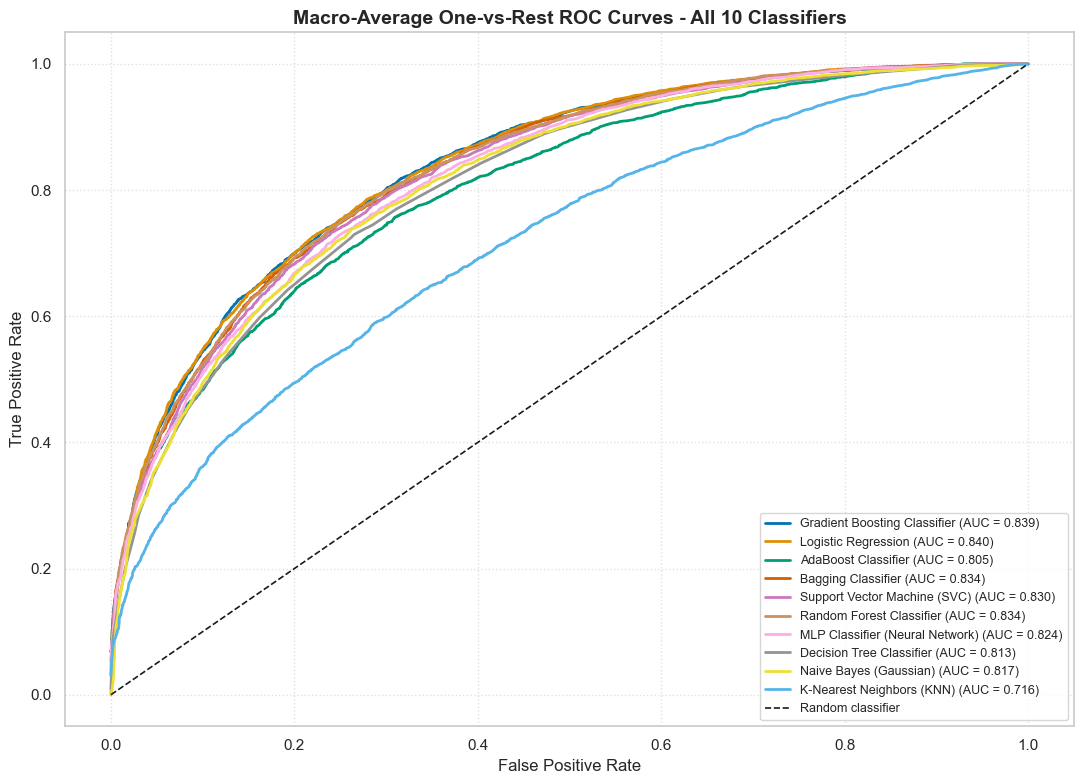

In [70]:
def plot_macro_roc(prob_by_model, y_true, title):
    """Macro-averaged One-vs-Rest ROC curve for every model in prob_by_model."""
    class_ids = np.unique(y_true)
    y_bin = label_binarize(y_true, classes=class_ids)
    fig, ax = plt.subplots(figsize=(11, 8))
    macro_aucs = {}

    for color, (name, prob) in zip(PALETTE, prob_by_model.items()):
        macro_aucs[name] = roc_auc_score(y_true, prob, multi_class="ovr", average="macro")
        fpr, tpr = {}, {}
        for i in range(len(class_ids)):
            fpr[i], tpr[i], _ = roc_curve(y_bin[:, i], prob[:, i])
        grid_fpr = np.unique(np.concatenate([fpr[i] for i in range(len(class_ids))]))
        mean_tpr = np.mean([np.interp(grid_fpr, fpr[i], tpr[i]) for i in range(len(class_ids))], axis=0)
        ax.plot(grid_fpr, mean_tpr, color=color, lw=2, label=f"{name} (AUC = {macro_aucs[name]:.3f})")

    ax.plot([0, 1], [0, 1], "k--", lw=1.2, label="Random classifier")
    ax.set_title(title, fontsize=14, weight="bold")
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.legend(loc="lower right", fontsize=9)
    ax.grid(True, linestyle=":", alpha=0.6)
    plt.tight_layout()
    plt.show()
    return macro_aucs


ordered_probs = {name: class_probabilities[name] for name in comparison_df["Algorithm"]}
macro_auc_all = plot_macro_roc(ordered_probs, y_class_test, "Macro-Average One-vs-Rest ROC Curves - All 10 Classifiers")

## E8 — Final Model Selection, Cross-Validation & Hyper-parameter Tuning Evidence

The final model is chosen with a transparent rule: **highest weighted F1-score on the shared test split (ROC-AUC as tie-breaker)**. To confirm the ranking is not an artefact of a single split, **5-fold stratified cross-validation** is run on the training data for the top two models. Finally, the tuning evidence for the selected model is shown as *before vs. after* metrics:

* if the selected model is a **Part-B** model, its default-vs-tuned results from E6 are used;
* if it is a **Part-A** model that was not tuned in Review 1, a `GridSearchCV` is run here (5-fold) and compared against its Review-1 result.

In [71]:
# ------------------------------------------------------------
# 1) Identify the top two models from the consolidated table
# ------------------------------------------------------------
best_name = comparison_df.loc[0, "Algorithm"]
runner_up_name = comparison_df.loc[1, "Algorithm"]
print("Selected (rank 1):", best_name)
print("Runner-up (rank 2):", runner_up_name)


# ------------------------------------------------------------
# 2) 5-fold stratified CV on the TRAINING split for the top two models
# ------------------------------------------------------------
def five_fold_summary(name):
    estimator = clone(trained_classifiers[name])
    if "probability" in estimator.get_params():
        estimator.set_params(probability=False)      # not needed for CV scoring; much faster for SVC
    cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    scores = cross_validate(
        estimator, X_class_train_processed, y_class_train, cv=cv5,
        scoring={"accuracy": "accuracy", "f1": "f1_weighted"}, n_jobs=-1
    )
    return {
        "Algorithm": name,
        "CV Accuracy (mean)": scores["test_accuracy"].mean(),
        "CV Accuracy (std)": scores["test_accuracy"].std(),
        "CV Weighted F1 (mean)": scores["test_f1"].mean(),
        "CV Weighted F1 (std)": scores["test_f1"].std(),
    }


cv_top2 = pd.DataFrame([five_fold_summary(best_name), five_fold_summary(runner_up_name)])
print("\n5-fold stratified cross-validation (top two models):")
display(cv_top2.round(4))
cv_top2.to_csv(f"{RESULTS_DIR}/classification_top2_cv.csv", index=False)

Selected (rank 1): Gradient Boosting Classifier
Runner-up (rank 2): Logistic Regression

5-fold stratified cross-validation (top two models):


,Algorithm,CV Accuracy (mean),CV Accuracy (std),CV Weighted F1 (mean),CV Weighted F1 (std)
0,Gradient Boosting Classifier,0.6707,0.0084,0.6676,0.0079
1,Logistic Regression,0.6736,0.0072,0.6703,0.0068


In [72]:
# ------------------------------------------------------------
# 3) Hyper-parameter tuning evidence for the selected model
# ------------------------------------------------------------
# Search spaces for Part-A models not already tuned in the main comparison
part_a_specs = {
    "Logistic Regression": (
        LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
        {"C": [0.01, 0.1, 1, 10, 100], "class_weight": [None, "balanced"]}),
    "Naive Bayes (Gaussian)": (
        GaussianNB(),
        {"var_smoothing": np.logspace(-11, -5, 7)}),
    "Decision Tree Classifier": (
        DecisionTreeClassifier(random_state=RANDOM_STATE),
        {"max_depth": [3, 4, 5, 6, 8], "min_samples_leaf": [5, 20, 50]}),
    "Support Vector Machine (SVC)": (
        SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE),
        {"C": [0.5, 1, 5, 10], "gamma": ["scale", 0.01]}),
}


def metric_triplet(model):
    pred = model.predict(X_class_test_processed)
    prob = model.predict_proba(X_class_test_processed)
    return {
        "Accuracy": accuracy_score(y_class_test, pred),
        "Weighted F1": f1_score(y_class_test, pred, average="weighted"),
        "ROC-AUC (OvR)": roc_auc_score(y_class_test, prob, multi_class="ovr", average="weighted"),
    }


if best_name in PART_B_NAMES:
    # Tuning already carried out in E1-E5 -> reuse the logged default-vs-tuned results
    log = part_b_tuning_df.set_index("Algorithm").loc[best_name]
    before = {"Accuracy": log["Default Accuracy"], "Weighted F1": log["Default F1"], "ROC-AUC (OvR)": log["Default ROC-AUC"]}
    after = {"Accuracy": log["Tuned Accuracy"], "Weighted F1": log["Tuned F1"], "ROC-AUC (OvR)": log["Tuned ROC-AUC"]}
    final_model = trained_classifiers[best_name]
    final_params = log["Best Parameters"]
    before_label = "Default hyper-parameters"
elif best_name == "K-Nearest Neighbors (KNN)":
    # KNN was already tuned in the Part-A comparison; reuse that fitted search.
    # This avoids running a second KNN GridSearchCV with a different grid.
    final_model = best_knn_classifier
    final_params = str(knn_grid.best_params_)
    after = metric_triplet(final_model)
    before = after.copy()
    before_label = "Existing tuned configuration"
else:
    # Part-A model that was not tuned in Review 1 -> run a 5-fold grid search now
    base_estimator, grid = part_a_specs[best_name]
    search_estimator = clone(base_estimator)
    if "probability" in search_estimator.get_params():
        search_estimator.set_params(probability=False)   # speeds up the search; restored below
    final_search = GridSearchCV(
        search_estimator, grid, scoring="f1_weighted",
        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
        n_jobs=-1, refit=False
    )
    final_search.fit(X_class_train_processed, y_class_train)
    final_model = clone(base_estimator).set_params(**final_search.best_params_)
    final_model.fit(X_class_train_processed, y_class_train)
    row = comparison_df.loc[0]
    before = {"Accuracy": row["Accuracy"], "Weighted F1": row["F1-score (Weighted)"], "ROC-AUC (OvR)": row["ROC-AUC (OvR)"]}
    after = metric_triplet(final_model)
    final_params = str(final_search.best_params_)
    before_label = "Review-1 configuration"
    trained_classifiers[best_name] = final_model

tuning_effect_df = pd.DataFrame({
    "Metric": list(before.keys()),
    before_label: [before[k] for k in before],
    "After tuning": [after[k] for k in before],
})
tuning_effect_df["Change"] = tuning_effect_df["After tuning"] - tuning_effect_df[before_label]

print(f"Final model: {best_name}")
print(f"Best hyper-parameters: {final_params}\n")
display(tuning_effect_df.round(4))
tuning_effect_df.round(4).to_csv(f"{RESULTS_DIR}/final_model_tuning_effect.csv", index=False)

MEANINGFUL_CHANGE = 1e-4
gains = tuning_effect_df[tuning_effect_df["Change"] > MEANINGFUL_CHANGE]["Metric"].tolist()
if gains:
    print("Tuning improved:", ", ".join(gains))
else:
    print("Tuning produced no meaningful change for this model (the starting configuration was already near-optimal).")
    print("Default-vs-tuned improvements for all five Part-B models are documented in the E6 table above.")

Final model: Gradient Boosting Classifier
Best hyper-parameters: {'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 200}



,Metric,Default hyper-parameters,After tuning,Change
0,Accuracy,0.6766,0.6773,0.0007
1,Weighted F1,0.6742,0.6747,0.0006
2,ROC-AUC (OvR),0.8228,0.8239,0.0010


Tuning improved: Accuracy, Weighted F1, ROC-AUC (OvR)


FINAL MODEL: Gradient Boosting Classifier
              precision    recall  f1-score   support

        High     0.7884    0.6776    0.7288       825
         Low     0.7102    0.7902    0.7481      1969
      Medium     0.5767    0.5386    0.5570      1606

    accuracy                         0.6773      4400
   macro avg     0.6918    0.6688    0.6780      4400
weighted avg     0.6761    0.6773    0.6747      4400



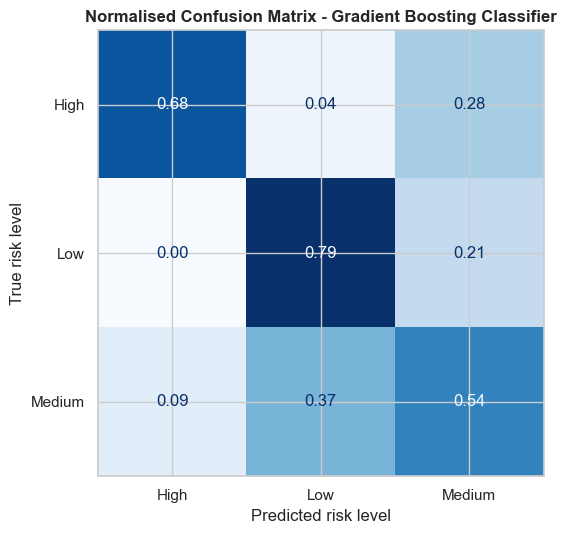


JUSTIFICATION FOR FINAL MODEL SELECTION
----------------------------------------------------------------------
* Gradient Boosting Classifier ranks #1 of 10 on weighted F1 (0.6747), ahead of Logistic Regression (0.6731); gap = 0.0016.
* Test accuracy 0.6773, weighted ROC-AUC 0.8239.
* 5-fold CV weighted F1 = 0.6676 +/- 0.0079 (a small std indicates stable performance across folds).
* Recall on the critical 'High' risk class: 67.76%.

Saved: ..\models/final_classifier.pkl


In [73]:
# ------------------------------------------------------------
# 4) Final evaluation of the selected model on the held-out test split
# ------------------------------------------------------------
y_pred_final = final_model.predict(X_class_test_processed)

print("=" * 70)
print(f"FINAL MODEL: {best_name}")
print("=" * 70)
print(classification_report(y_class_test, y_pred_final, target_names=label_encoder.classes_, digits=4))

cm_final = confusion_matrix(y_class_test, y_pred_final, normalize="true")
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ConfusionMatrixDisplay(cm_final, display_labels=label_encoder.classes_).plot(
    ax=ax, cmap="Blues", values_format=".2f", colorbar=False
)
ax.set_title(f"Normalised Confusion Matrix - {best_name}", fontsize=12, weight="bold")
ax.set_xlabel("Predicted risk level")
ax.set_ylabel("True risk level")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 5) Justification printed from the actual results
# ------------------------------------------------------------
top, second = comparison_df.loc[0], comparison_df.loc[1]
cv_best = cv_top2.iloc[0]
print("\nJUSTIFICATION FOR FINAL MODEL SELECTION")
print("-" * 70)
print(f"* {best_name} ranks #1 of 10 on weighted F1 ({top['F1-score (Weighted)']:.4f}), "
      f"ahead of {runner_up_name} ({second['F1-score (Weighted)']:.4f}); "
      f"gap = {top['F1-score (Weighted)'] - second['F1-score (Weighted)']:.4f}.")
print(f"* Test accuracy {top['Accuracy']:.4f}, weighted ROC-AUC {top['ROC-AUC (OvR)']:.4f}.")
print(f"* 5-fold CV weighted F1 = {cv_best['CV Weighted F1 (mean)']:.4f} +/- {cv_best['CV Weighted F1 (std)']:.4f} "
      f"(a small std indicates stable performance across folds).")
high_idx = list(label_encoder.classes_).index("High")
print(f"* Recall on the critical 'High' risk class: {cm_final[high_idx, high_idx]:.2%}.")

# ------------------------------------------------------------
# 6) Save the final model bundle for reuse (optional repository artefact / GUI bonus)
# ------------------------------------------------------------
joblib.dump(
    {
        "model": final_model,
        "preprocessor": class_preprocessor,
        "label_encoder": label_encoder,
        "feature_columns": X_class.columns.tolist(),
        "model_name": best_name,
    },
    f"{MODELS_DIR}/final_classifier.pkl",
    compress=3,   # smaller file (GitHub rejects files above 100 MB)
)
print(f"\nSaved: {MODELS_DIR}/final_classifier.pkl")


## E9 — Final Classification Summary & Domain Interpretation

This section consolidates the classification workflow, measured outcomes, tuning results and
manufacturing-domain interpretation from the fitted notebook objects.


In [74]:
print("=" * 96)
print("FINAL CLASSIFICATION SUMMARY - MAINTENANCE RISK PREDICTION")
print("=" * 96)

final_report = classification_report(y_class_test, y_pred_final, target_names=label_encoder.classes_, output_dict=True, zero_division=0)
final_row = comparison_df.loc[comparison_df["Algorithm"] == best_name].iloc[0]
class_metrics = pd.DataFrame(final_report).T.loc[
    [c for c in label_encoder.classes_ if c in final_report],
    ["precision", "recall", "f1-score", "support"]
]

print("\n1. WORKFLOW COMPLETED")
print(f"   Records analysed       : {len(df):,}")
print(f"   Training / test rows   : {len(y_class_train):,} / {len(y_class_test):,}")
print("   Preprocessing           : imputation, ordinal encoding and StandardScaler")
print("   Models compared        : 5 Part-A + 5 tuned Part-B classifiers")
print("   Metrics                : accuracy, precision, recall, weighted F1 and OvR ROC-AUC")

print("\n2. FINAL OUTCOME")
print(f"   Selected model         : {best_name}")
print(f"   Accuracy               : {final_row['Accuracy']:.4f}")
print(f"   Weighted F1            : {final_row['F1-score (Weighted)']:.4f}")
print(f"   Weighted ROC-AUC       : {final_row['ROC-AUC (OvR)']:.4f}")
print(f"   Runner-up              : {runner_up_name}")
print(f"   Weighted F1 gap        : {top['F1-score (Weighted)'] - second['F1-score (Weighted)']:.4f}")
display(comparison_df[["Rank", "Algorithm", "Part", "Accuracy", "F1-score (Weighted)", "ROC-AUC (OvR)"]].round(4))

print("3. CLASS-LEVEL PERFORMANCE")
display(class_metrics.round(4))
print(f"   High-risk recall       : {final_report['High']['recall']:.2%}")
print(f"   Medium-risk recall     : {final_report['Medium']['recall']:.2%}")

print("4. CROSS-VALIDATION AND TUNING")
display(cv_top2.round(4))
display(part_b_tuning_view.round(4))
print("   Top-two CV checks stability; Part-B GridSearchCV selects hyperparameters.")

risk_distribution = df["maintenance_risk"].value_counts(normalize=True).mul(100).round(2)
top_odds_feature = str(coef_df.iloc[0]["Feature"]).replace("num__", "")
top_odds_value = float(coef_df.iloc[0]["Odds_Ratio"])
top_rf_features = [str(x).replace("num__", "").replace("cat__", "") for x in rf_clf_importance["Feature"].head(5)]

print("5. MANUFACTURING-DOMAIN OBSERVATIONS")
print(f"   Risk distribution       : {risk_distribution.to_dict()}")
print(f"   Strongest odds-ratio signal: {top_odds_feature} ({top_odds_value:.2f}x)")
print(f"   Random Forest top features: {', '.join(top_rf_features)}")
print("   • Longer time since maintenance is consistent with overdue service and increased failure risk.")
print("   • Machine age reflects accumulated wear and supports shorter inspection intervals for older assets.")
print("   • Bearing temperature and bearing temperature rise indicate friction, lubrication problems or bearing wear.")
print("   • Vibration is consistent with imbalance, looseness, misalignment or mechanical deterioration.")
print("   • Downtime and defect rate capture operational degradation and production-quality disruption.")
print("   • Motor current and load represent electrical/mechanical stress and sustained operating demand.")

print("6. OPERATIONAL INTERPRETATION")
print("   The model is a maintenance-screening tool, not a replacement for engineering inspection.")
print("   Low risk is detected most reliably; Medium risk is the hardest class because it is a transition zone.")
print("   High-risk recall is operationally important because missed critical machines can be costly.")
print("   Odds ratios and feature importance show predictive association, not proof of causation.")
print("   Future deployment should monitor class-specific recall, calibration and sensor/data drift.")

print("7. SAVED ARTEFACTS")
if os.path.exists(RESULTS_DIR):
    for fname in sorted(os.listdir(RESULTS_DIR)):
        if "classification" in fname or "tuning" in fname or "part_b" in fname:
            print(f"   {RESULTS_DIR}/{fname}")
print(f"   {MODELS_DIR}/final_classifier.pkl")
print("=" * 96)

FINAL CLASSIFICATION SUMMARY - MAINTENANCE RISK PREDICTION

1. WORKFLOW COMPLETED
   Records analysed       : 22,260
   Training / test rows   : 17,600 / 4,400
   Preprocessing           : imputation, ordinal encoding and StandardScaler
   Models compared        : 5 Part-A + 5 tuned Part-B classifiers
   Metrics                : accuracy, precision, recall, weighted F1 and OvR ROC-AUC

2. FINAL OUTCOME
   Selected model         : Gradient Boosting Classifier
   Accuracy               : 0.6773
   Weighted F1            : 0.6747
   Weighted ROC-AUC       : 0.8239
   Runner-up              : Logistic Regression
   Weighted F1 gap        : 0.0016


,Rank,Algorithm,Part,Accuracy,F1-score (Weighted),ROC-AUC (OvR)
0,1,Gradient Boosting Classifier,B,0.6773,0.6747,0.8239
1,2,Logistic Regression,A,0.6759,0.6731,0.8241
2,3,AdaBoost Classifier,B,0.6709,0.6709,0.7863
3,4,Bagging Classifier,B,0.6716,0.6683,0.8184
4,5,Support Vector Machine (SVC),A,0.6684,0.6650,0.8137
5,6,Random Forest Classifier,B,0.6709,0.6639,0.8192
6,7,MLP Classifier (Neural Network),B,0.6591,0.6580,0.8069
7,8,Decision Tree Classifier,A,0.6536,0.6531,0.7957
8,9,Naive Bayes (Gaussian),A,0.6527,0.6429,0.8007
9,10,K-Nearest Neighbors (KNN),A,0.5430,0.5276,0.6931


3. CLASS-LEVEL PERFORMANCE


,precision,recall,f1-score,support
High,0.7884,0.6776,0.7288,825.0
Low,0.7102,0.7902,0.7481,1969.0
Medium,0.5767,0.5386,0.5570,1606.0


   High-risk recall       : 67.76%
   Medium-risk recall     : 53.86%
4. CROSS-VALIDATION AND TUNING


,Algorithm,CV Accuracy (mean),CV Accuracy (std),CV Weighted F1 (mean),CV Weighted F1 (std)
0,Gradient Boosting Classifier,0.6707,0.0084,0.6676,0.0079
1,Logistic Regression,0.6736,0.0072,0.6703,0.0068


,Algorithm,Default F1,Tuned F1,F1 Change,Default Accuracy,Tuned Accuracy,Accuracy Change,ROC-AUC Change,CV F1 (best),Best Parameters
0,Random Forest Classifier,0.6652,0.6639,-0.0013,0.6702,0.6709,0.0007,0.0072,0.6623,"{'max_depth': 15, 'n_estimators': 300}"
1,AdaBoost Classifier,0.6612,0.6709,0.0097,0.6657,0.6709,0.0052,0.0197,0.6662,"{'estimator__max_depth': 2, 'learning_rate': 0..."
2,Gradient Boosting Classifier,0.6742,0.6747,0.0006,0.6766,0.6773,0.0007,0.0010,0.6688,"{'learning_rate': 0.1, 'max_depth': 2, 'n_esti..."
3,Bagging Classifier,0.6580,0.6683,0.0103,0.6618,0.6716,0.0098,0.0123,0.6649,"{'estimator__max_depth': 10, 'max_samples': 0...."
4,MLP Classifier (Neural Network),0.6697,0.6580,-0.0117,0.6670,0.6591,-0.0080,-0.0105,0.6686,"{'activation': 'tanh', 'alpha': 0.01, 'hidden_..."


   Top-two CV checks stability; Part-B GridSearchCV selects hyperparameters.
5. MANUFACTURING-DOMAIN OBSERVATIONS
   Risk distribution       : {'Low': 44.73, 'Medium': 36.5, 'High': 18.76}
   Strongest odds-ratio signal: days_since_maintenance (8.39x)
   Random Forest top features: days_since_maintenance, machine_age_years, operator_experience_years, bearing_temperature_c, defect_rate_pct
   • Longer time since maintenance is consistent with overdue service and increased failure risk.
   • Machine age reflects accumulated wear and supports shorter inspection intervals for older assets.
   • Bearing temperature and bearing temperature rise indicate friction, lubrication problems or bearing wear.
   • Vibration is consistent with imbalance, looseness, misalignment or mechanical deterioration.
   • Downtime and defect rate capture operational degradation and production-quality disruption.
   • Motor current and load represent electrical/mechanical stress and sustained operating demand.
6.